# Mini Project: Lakehouse Research Assistant (GenAI + RAG + Agents)
**Author:** Asit Kar · Post Graduate Program in AI and Machine Learning, Weeks 35–36

An **Intelligent Research Assistant for data-engineering and lakehouse architecture**. It ingests 13 foundational systems papers (MapReduce, GFS, Bigtable, Dremel, Spark/RDD, Spark SQL, Structured Streaming, Delta Lake, Lakehouse, Photon, Deequ, LHBench and a data-lake survey). It then answers questions grounded in those papers, searches the web when the papers are not enough, and writes structured, cited research reports.

**Stack (free, no API keys):**

| Layer | Choice |
|---|---|
| LLM (generation + agents) | `qwen2.5:7b` served by **Ollama** on a Colab T4 GPU (`ChatOllama`) |
| LLM judge (evaluation) | `llama3.1:8b`, a different model family, so the generator never grades itself |
| Embeddings | `sentence-transformers/all-MiniLM-L6-v2` (`HuggingFaceEmbeddings`) |
| Vector store | **Chroma**, persisted to disk |
| Web search | DuckDuckGo (`ddgs`), with a Wikipedia fallback |
| Orchestration | LangChain 1.x (LCEL, `create_agent`) and **LangGraph** (`StateGraph`, `MemorySaver`, `interrupt_before`) |

**Sections follow the milestones:** 1A Corpus & ingestion → 1B Vector store & retrieval → 1C Prompt engineering → 2A Tool-augmented agent → 2B Multi-agent report system → 2C Human-in-the-loop & guardrails → 2D Evaluation, ablation & failure analysis.

> **Why two models?** A first full run used Llama 3.1 8B for everything. In Task 10 it never escalated to web search and invented an Apache Iceberg version number. It also broke the report JSON on long outputs, and as a judge it scored itself 5/5 almost everywhere. Qwen 2.5 7B handled all four agent query types (the model-by-prompt comparison is kept in Task 10), so it became the generator. Llama 3.1 8B is kept as an independent judge after a sanity check showed it catches an injected false claim (Task 15).

> Run on Google Colab with a **T4 GPU** runtime (Runtime → Change runtime type). A full run takes about an hour, mostly LLM generation. During development the pipeline was smoke-tested offline with a fake chat model (`TEST_MODE`), as the project tips suggest.

## 0. Setup

In [1]:
import os, sys, subprocess, time, json, re, math, shutil, textwrap, warnings
from datetime import datetime, timezone

warnings.filterwarnings('ignore')
TEST_MODE = os.environ.get('MINIPROJECT_TEST_MODE') == '1'   # offline smoke test with a fake LLM (development only)
MODEL_NAME = 'qwen2.5:7b'       # generator and agents
JUDGE_MODEL = 'llama3.1:8b'     # independent evaluator
WORK_DIR = os.environ.get('MINIPROJECT_DIR', '/content' if os.path.isdir('/content') else os.getcwd())
CORPUS_DIR = os.path.join(WORK_DIR, 'corpus')
CHROMA_DIR = os.path.join(WORK_DIR, 'chroma_db')
os.makedirs(CORPUS_DIR, exist_ok=True)


def sh(cmd):
    # Run a shell command quietly; raise with the tail of the output if it fails
    res = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(f'{cmd}\n{res.stdout[-1500:]}\n{res.stderr[-1500:]}')
    return res.stdout


if not TEST_MODE:
    sh('pip install -q "langchain==1.4.7" "langchain-core==1.7.0" "langchain-community==0.4.2" '
       '"langchain-text-splitters==1.1.3" "langgraph==1.2.18" "langchain-ollama==1.1.0" '
       '"langchain-chroma==1.1.0" "langchain-huggingface==1.2.3" chromadb tiktoken pypdf ddgs '
       'sentence-transformers json-repair')
print('Python', sys.version.split()[0], '| TEST_MODE =', TEST_MODE)

Python 3.13.16 | TEST_MODE = False


In [2]:
# Install and start the Ollama server, then pull the model (about 5 GB, 1-3 minutes on Colab)
import urllib.request

def ollama_up():
    try:
        urllib.request.urlopen('http://localhost:11434', timeout=2)
        return True
    except Exception:
        return False

if not TEST_MODE:
    if shutil.which('ollama') is None:
        sh('apt-get -qq update && apt-get -qq install -y zstd pciutils lshw > /dev/null')
        sh('curl -fsSL https://ollama.com/install.sh | sh')
    if not ollama_up():
        subprocess.Popen(['ollama', 'serve'], stdout=open('/tmp/ollama.log', 'w'), stderr=subprocess.STDOUT,
                         env={**os.environ, 'OLLAMA_KEEP_ALIVE': '60m'})
        for _ in range(60):
            if ollama_up():
                break
            time.sleep(1)
    sh(f'ollama pull {MODEL_NAME}')
    sh(f'ollama pull {JUDGE_MODEL}')
    print(sh('ollama list'))
    print(sh('nvidia-smi --query-gpu=name,memory.total --format=csv,noheader'))

NAME           ID              SIZE      MODIFIED               
llama3.1:8b    46e0c10c039e    4.9 GB    Less than a second ago    
qwen2.5:7b     845dbda0ea48    4.7 GB    51 seconds ago            

Tesla T4, 15360 MiB



In [3]:
import numpy as np
import pandas as pd
from typing import Annotated, Optional, TypedDict
from pydantic import BaseModel, Field
from IPython.display import display, Markdown

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough, RunnableParallel, RunnableLambda
from langchain_core.messages import HumanMessage, AIMessage, ToolMessage, SystemMessage
from langchain_core.tools import tool
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.tracers.context import register_configure_hook
from contextvars import ContextVar
from langchain_chroma import Chroma
from langchain.agents import create_agent
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

In [4]:
# LLM factory. Temperature 0 and a fixed seed make runs as repeatable as a local LLM allows.
if TEST_MODE:
    from fake_llm import FakeChatModel            # development-only fake (not part of the submission)

def make_llm(model=MODEL_NAME, num_predict=1024):
    if TEST_MODE:
        return FakeChatModel()
    from langchain_ollama import ChatOllama
    return ChatOllama(model=model, temperature=0, seed=42, num_ctx=8192, num_predict=num_predict)

llm = make_llm()                                       # qwen2.5:7b: RAG chains and agents
writer_llm = make_llm(num_predict=2048)                # longer budget for the structured report
judge_llm = make_llm(JUDGE_MODEL, num_predict=700)     # llama3.1:8b: evaluation only

# Pricing used only to estimate what the same token volume would cost on a hosted API.
# The local Ollama model itself costs $0 per token. Assumed gpt-4o-mini list price (USD per 1M tokens):
PRICE_IN, PRICE_OUT = 0.15, 0.60


class TokenCounter(BaseCallbackHandler):
    # Sums input/output tokens reported in usage_metadata by every LLM call made while it is active
    def __init__(self):
        self.input_tokens = self.output_tokens = self.calls = 0

    def on_llm_end(self, response, **kwargs):
        for generations in response.generations:
            for gen in generations:
                usage = getattr(getattr(gen, 'message', None), 'usage_metadata', None) or {}
                self.input_tokens += usage.get('input_tokens', 0)
                self.output_tokens += usage.get('output_tokens', 0)
                self.calls += 1


_token_counter = ContextVar('token_counter', default=None)
register_configure_hook(_token_counter, inheritable=True)   # attaches the counter to every run, incl. LangGraph nodes


def tracked(fn, *args, **kwargs):
    # Run fn and return (result, seconds, input_tokens, output_tokens)
    counter = TokenCounter()
    token = _token_counter.set(counter)
    try:
        start = time.perf_counter()
        result = fn(*args, **kwargs)
        seconds = time.perf_counter() - start
    finally:
        _token_counter.reset(token)
    return result, seconds, counter.input_tokens, counter.output_tokens


print(llm.invoke('In one sentence, what is a data lakehouse?').content)

A data lakehouse is a unified architecture that combines the raw storage capabilities of a data lake with the structured processing and governance features of a data warehouse, enabling efficient data ingestion, storage, and analysis.


---
# Milestone 1A: Document corpus and ingestion
## Task 1: Corpus
**Domain:** data engineering and lakehouse architecture. I work as a data & analytics architect on Databricks lakehouse platforms, and these are the papers the platform is built on. An assistant that can answer "why does Delta Lake do X?" from the primary sources, with page-level citations, is useful in architecture reviews.

**Corpus:** 13 peer-reviewed systems papers (free PDFs from the authors' or venues' sites), downloaded at run time and not redistributed in the repo.

In [5]:
# (filename, title, candidate URLs); the first URL that returns a PDF is used
CORPUS = [
    ('mapreduce_osdi2004.pdf', 'MapReduce: Simplified Data Processing on Large Clusters (OSDI 2004)',
     ['https://static.googleusercontent.com/media/research.google.com/en//archive/mapreduce-osdi04.pdf']),
    ('gfs_sosp2003.pdf', 'The Google File System (SOSP 2003)',
     ['https://static.googleusercontent.com/media/research.google.com/en//archive/gfs-sosp2003.pdf']),
    ('bigtable_osdi2006.pdf', 'Bigtable: A Distributed Storage System for Structured Data (OSDI 2006)',
     ['https://static.googleusercontent.com/media/research.google.com/en//archive/bigtable-osdi06.pdf']),
    ('dremel_vldb2010.pdf', 'Dremel: Interactive Analysis of Web-Scale Datasets (VLDB 2010)',
     ['https://static.googleusercontent.com/media/research.google.com/en//pubs/archive/36632.pdf']),
    ('rdd_nsdi2012.pdf', 'Resilient Distributed Datasets (NSDI 2012)',
     ['https://www.usenix.org/system/files/conference/nsdi12/nsdi12-final138.pdf']),
    ('spark_sql_sigmod2015.pdf', 'Spark SQL: Relational Data Processing in Spark (SIGMOD 2015)',
     ['https://people.csail.mit.edu/matei/papers/2015/sigmod_spark_sql.pdf',
      'https://people.eecs.berkeley.edu/~matei/papers/2015/sigmod_spark_sql.pdf']),
    ('structured_streaming_sigmod2018.pdf', 'Structured Streaming (SIGMOD 2018)',
     ['https://people.eecs.berkeley.edu/~matei/papers/2018/sigmod_structured_streaming.pdf',
      'https://cs.stanford.edu/~matei/papers/2018/sigmod_structured_streaming.pdf']),
    ('deequ_vldb2018.pdf', 'Automating Large-Scale Data Quality Verification (Deequ, VLDB 2018)',
     ['https://www.vldb.org/pvldb/vol11/p1781-schelter.pdf']),
    ('delta_lake_vldb2020.pdf', 'Delta Lake: High-Performance ACID Table Storage over Cloud Object Stores (VLDB 2020)',
     ['https://www.vldb.org/pvldb/vol13/p3411-armbrust.pdf']),
    ('lakehouse_cidr2021.pdf', 'Lakehouse: A New Generation of Open Platforms (CIDR 2021)',
     ['https://www.cidrdb.org/cidr2021/papers/cidr2021_paper17.pdf']),
    ('photon_sigmod2022.pdf', 'Photon: A Fast Query Engine for Lakehouse Systems (SIGMOD 2022)',
     ['https://people.eecs.berkeley.edu/~matei/papers/2022/sigmod_photon.pdf',
      'https://cs.stanford.edu/~matei/papers/2022/sigmod_photon.pdf']),
    ('lhbench_cidr2023.pdf', 'Analyzing and Comparing Lakehouse Storage Systems (CIDR 2023)',
     ['https://www.cidrdb.org/cidr2023/papers/p92-jain.pdf']),
    ('data_lakes_survey_2021.pdf', 'Data Lakes: A Survey of Functions and Systems (arXiv 2106.09592)',
     ['https://arxiv.org/pdf/2106.09592']),
]
TITLES = {fname: title for fname, title, _ in CORPUS}


def download(fname, urls):
    path = os.path.join(CORPUS_DIR, fname)
    if os.path.exists(path) and os.path.getsize(path) > 10_000:
        return path, 'cached'
    for url in urls:
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (research-assistant mini project)'})
            data = urllib.request.urlopen(req, timeout=60).read()
            if data[:4] == b'%PDF':
                open(path, 'wb').write(data)
                return path, url
        except Exception as exc:
            last_error = exc
    return None, 'failed'


if TEST_MODE:
    from fake_llm import make_fake_corpus
    make_fake_corpus(CORPUS_DIR, [c[0] for c in CORPUS])

rows = []
for fname, title, urls in CORPUS:
    path, origin = (os.path.join(CORPUS_DIR, fname), 'test') if TEST_MODE else download(fname, urls)
    rows.append({'file': fname, 'title': title, 'status': 'ok' if path else 'FAILED',
                 'size_kb': round(os.path.getsize(path) / 1024) if path else 0})
corpus_df = pd.DataFrame(rows)
corpus_files = corpus_df.loc[corpus_df['status'] == 'ok', 'file'].tolist()
print(f'{len(corpus_files)} of {len(CORPUS)} documents available')
corpus_df

13 of 13 documents available


,file,title,status,size_kb
0,mapreduce_osdi2004.pdf,MapReduce: Simplified Data Processing on Large Clusters (OSDI 2004),ok,186
1,gfs_sosp2003.pdf,The Google File System (SOSP 2003),ok,269
2,bigtable_osdi2006.pdf,Bigtable: A Distributed Storage System for Structured Data (OSDI 2006),ok,216
3,dremel_vldb2010.pdf,Dremel: Interactive Analysis of Web-Scale Datasets (VLDB 2010),ok,1222
4,rdd_nsdi2012.pdf,Resilient Distributed Datasets (NSDI 2012),ok,866
5,spark_sql_sigmod2015.pdf,Spark SQL: Relational Data Processing in Spark (SIGMOD 2015),ok,508
6,structured_streaming_sigmod2018.pdf,Structured Streaming (SIGMOD 2018),ok,745
7,deequ_vldb2018.pdf,"Automating Large-Scale Data Quality Verification (Deequ, VLDB 2018)",ok,1025
8,delta_lake_vldb2020.pdf,Delta Lake: High-Performance ACID Table Storage over Cloud Object Stores (VLDB 2020),ok,418
9,lakehouse_cidr2021.pdf,Lakehouse: A New Generation of Open Platforms (CIDR 2021),ok,708


## Task 2: Ingestion pipeline and chunking comparison
`PyPDFLoader` loads each PDF page as a `Document`. Two-column PDF extraction breaks words across lines with hyphens and adds stray whitespace, so a light cleaning step re-joins hyphenated words and collapses whitespace before chunking.

In [6]:
def clean_text(text):
    text = re.sub(r'(\w)-\n(\w)', r'\1\2', text)        # re-join words hyphenated across lines
    text = re.sub(r'[ \t]*\n[ \t]*', '\n', text)
    text = re.sub(r'(?<!\n)\n(?!\n)', ' ', text)         # single newlines inside paragraphs -> space
    return re.sub(r'[ \t]{2,}', ' ', text).strip()


pages = []
for fname in corpus_files:
    for page in PyPDFLoader(os.path.join(CORPUS_DIR, fname)).load():
        text = clean_text(page.page_content)
        if len(text) > 50:                                # skip blank pages
            pages.append(Document(page_content=text,
                                  metadata={'source': fname, 'page': page.metadata.get('page', 0) + 1,
                                            'title': TITLES[fname]}))

pages_per_doc = pd.Series([p.metadata['source'] for p in pages]).value_counts()
PAGE_COUNT = pages_per_doc.to_dict()
print(f'Loaded {len(pages)} pages from {len(corpus_files)} documents '
      f'({sum(len(p.page_content) for p in pages):,} characters)')
pages_per_doc.rename('pages').to_frame().T

Loaded 167 pages from 13 documents (968,171 characters)


,data_lakes_survey_2021.pdf,gfs_sosp2003.pdf,rdd_nsdi2012.pdf,delta_lake_vldb2020.pdf,bigtable_osdi2006.pdf,photon_sigmod2022.pdf,deequ_vldb2018.pdf,structured_streaming_sigmod2018.pdf,mapreduce_osdi2004.pdf,spark_sql_sigmod2015.pdf,dremel_vldb2010.pdf,lakehouse_cidr2021.pdf,lhbench_cidr2023.pdf
pages,20,15,14,14,14,14,14,13,13,12,10,8,6


In [7]:
try:
    import tiktoken
    _enc = tiktoken.get_encoding('cl100k_base')
    count_tokens = lambda text: len(_enc.encode(text))
except Exception:                                         # offline fallback (TEST_MODE only)
    count_tokens = lambda text: max(1, len(text) // 4)

STRATEGIES = {'A (1000 / 200)': dict(chunk_size=1000, chunk_overlap=200),
              'B (400 / 80)': dict(chunk_size=400, chunk_overlap=80)}

chunk_sets, stats = {}, []
for label, params in STRATEGIES.items():
    splitter = RecursiveCharacterTextSplitter(**params, separators=['\n\n', '\n', '. ', ' ', ''])
    chunks = splitter.split_documents(pages)
    tokens = np.array([count_tokens(c.page_content) for c in chunks])
    chunk_sets[label] = chunks
    stats.append({'strategy': label, 'chunks': len(chunks), 'avg_tokens': tokens.mean().round(1),
                  'median_tokens': np.median(tokens), 'min_tokens': tokens.min(), 'max_tokens': tokens.max()})
    shortest, longest = chunks[int(tokens.argmin())], chunks[int(tokens.argmax())]
    print(f'{label}: shortest ({tokens.min()} tokens) -> {shortest.page_content[:90]!r}')
    print(f'{label}: longest  ({tokens.max()} tokens) -> {longest.page_content[:90]!r}\n')

chunk_stats = pd.DataFrame(stats).set_index('strategy')
chunk_stats

A (1000 / 200): shortest (11 tokens) -> 'Table 2: Computable metrics to base constraints on'
A (1000 / 200): longest  (443 tokens) -> '. Error ) 7 . i s C o m p l e t e ( " c u s t o m e r I d " , " title " , 8 " i m p r e s '

B (400 / 80): shortest (1 tokens) -> '..'
B (400 / 80): longest  (272 tokens) -> 'Operation Read Wr i te Record Append Cluster XY XY XY 0K 0.4 2.6 00 00 1B..1K 0.1 4.1 6.6 '



,chunks,avg_tokens,median_tokens,min_tokens,max_tokens
strategy,,,,,
A (1000 / 200),1266,196.5,191.0,11,443
B (400 / 80),3223,72.2,69.0,1,272


**Choice: strategy A (1000 / 200).**
- A produces 1,266 chunks averaging 197 tokens. B produces 3,223 chunks averaging 72 tokens. The extremes (1–11 tokens, or 443 tokens for 1,000 characters) are PDF-extraction artefacts: table fragments, and Deequ's letter-spaced code listings, where every character becomes its own token.
- In these systems papers, a 1,000-character chunk is about one paragraph, so a mechanism and its justification stay together. B's 70-token chunks often cut an argument in half.
- With k = 4, A gives the LLM about 800 tokens of context per question, against about 300 for B. That is still far inside the 8k context window.
- MiniLM embeds up to 256 word-pieces. The median A chunk (191 tokens) fits, so only the artefact-heavy outliers are truncated.
- A also means 2.5× fewer vectors. Task 5 checks the choice on retrieval: A is equal or better.

## Task 3: Metadata enrichment
Every chunk carries `source` (filename), `page` (1-based, as printed in a PDF viewer), `chunk_index` (position within its document), `title` and a `date_ingested` timestamp. These fields are what the citations use later.

In [8]:
DATE_INGESTED = datetime.now(timezone.utc).isoformat(timespec='seconds')

def enrich(chunks):
    counters = {}
    for chunk in chunks:
        src = chunk.metadata['source']
        chunk.metadata['chunk_index'] = counters.get(src, 0)
        chunk.metadata['date_ingested'] = DATE_INGESTED
        counters[src] = counters.get(src, 0) + 1
    return chunks

for label in chunk_sets:
    enrich(chunk_sets[label])

chunks = chunk_sets['A (1000 / 200)']
print(chunks[42].metadata)

{'source': 'mapreduce_osdi2004.pdf', 'page': 8, 'title': 'MapReduce: Simplified Data Processing on Large Clusters (OSDI 2004)', 'chunk_index': 42, 'date_ingested': '2026-10-28T04:41:54+00:00'}


---
# Milestone 1B: Vector store and retrieval
## Task 4: Embeddings and Chroma vector store
`all-MiniLM-L6-v2` is free, fast on a GPU and good at short passages. Embeddings are L2-normalised and the collection uses cosine distance, so Chroma's relevance score is `1 - cosine distance`. The store is persisted to disk and reloaded on later runs instead of re-embedding.

In [9]:
if TEST_MODE:
    from langchain_core.embeddings import DeterministicFakeEmbedding
    embeddings = DeterministicFakeEmbedding(size=384)
else:
    import torch
    from langchain_huggingface import HuggingFaceEmbeddings
    embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2',
                                       model_kwargs={'device': 'cuda' if torch.cuda.is_available() else 'cpu'},
                                       encode_kwargs={'normalize_embeddings': True})


def build_store(name, docs):
    # Load the persisted collection if it is already complete, otherwise embed and persist
    store = Chroma(collection_name=name, embedding_function=embeddings, persist_directory=CHROMA_DIR,
                   collection_metadata={'hnsw:space': 'cosine'})
    if store._collection.count() != len(docs):
        if store._collection.count():
            store.delete_collection()
            store = Chroma(collection_name=name, embedding_function=embeddings, persist_directory=CHROMA_DIR,
                           collection_metadata={'hnsw:space': 'cosine'})
        ids = [f"{d.metadata['source']}::{d.metadata['chunk_index']}" for d in docs]
        for i in range(0, len(docs), 256):
            store.add_documents(docs[i:i + 256], ids=ids[i:i + 256])
    return store


start = time.perf_counter()
stores = {'A (1000 / 200)': build_store('lakehouse_a', chunk_sets['A (1000 / 200)']),
          'B (400 / 80)': build_store('lakehouse_b', chunk_sets['B (400 / 80)'])}
vectorstore = stores['A (1000 / 200)']
disk_mb = sum(os.path.getsize(os.path.join(root, f)) for root, _, files in os.walk(CHROMA_DIR) for f in files) / 1e6

print(f'Embedding dimension : {len(embeddings.embed_query("delta lake"))}')
print(f'Vectors stored      : {vectorstore._collection.count():,} (strategy A) | '
      f'{stores["B (400 / 80)"]._collection.count():,} (strategy B)')
print(f'Chroma size on disk : {disk_mb:.1f} MB (both collections) | build/load time {time.perf_counter() - start:.1f}s')

Embedding dimension : 384
Vectors stored      : 1,266 (strategy A) | 3,223 (strategy B)
Chroma size on disk : 32.2 MB (both collections) | build/load time 15.2s


## Task 5: Retrieval evaluation
Ten questions with known source documents and reference answers (`EVAL_SET`). They are reused for prompt engineering, end-to-end evaluation and the ablation. Because they name the system ("How does Delta Lake..."), a second set of ten **paraphrased** versions that do not name the system (`HARD_SET`) is used to stress the retrievers. A retrieved chunk counts as relevant when it comes from the question's source paper.

In [10]:
EVAL_SET = [
    {'id': 'Q1', 'source': 'mapreduce_osdi2004.pdf',
     'question': 'How does MapReduce handle the failure of a worker machine?',
     'answer': 'The master pings workers periodically; tasks on a failed worker are reset to idle and rescheduled. '
               'Completed map tasks are re-executed because their output is on the failed machine\'s local disk, '
               'while completed reduce tasks are not, since their output is in the global file system.'},
    {'id': 'Q2', 'source': 'gfs_sosp2003.pdf',
     'question': 'Why does the Google File System use a large 64 MB chunk size?',
     'answer': 'A large chunk size reduces client interaction with the master, reduces network overhead by keeping '
               'persistent TCP connections to a chunkserver, and keeps the metadata stored on the master small.'},
    {'id': 'Q3', 'source': 'rdd_nsdi2012.pdf',
     'question': 'How do Resilient Distributed Datasets recover lost data without replicating it?',
     'answer': 'RDDs log the coarse-grained transformations (lineage) used to build them, so a lost partition is '
               'recomputed from its parents instead of being restored from a replica.'},
    {'id': 'Q4', 'source': 'spark_sql_sigmod2015.pdf',
     'question': 'What is the Catalyst optimizer in Spark SQL and what phases does query planning go through?',
     'answer': 'Catalyst is an extensible optimizer built on Scala features such as pattern matching. Planning goes '
               'through analysis, logical optimization, physical planning and code generation.'},
    {'id': 'Q5', 'source': 'dremel_vldb2010.pdf',
     'question': 'How does Dremel store nested records in a columnar format?',
     'answer': 'Dremel stores each field as a column and records repetition levels and definition levels with each '
               'value, which allows the nested record structure to be reconstructed.'},
    {'id': 'Q6', 'source': 'structured_streaming_sigmod2018.pdf',
     'question': 'What is the main idea behind the Structured Streaming programming model?',
     'answer': 'A stream is treated as an unbounded table and users write ordinary Spark SQL/DataFrame queries, '
               'which the engine incrementalizes automatically, with end-to-end exactly-once semantics.'},
    {'id': 'Q7', 'source': 'delta_lake_vldb2020.pdf',
     'question': 'How does Delta Lake implement ACID transactions on cloud object storage?',
     'answer': 'Delta Lake keeps a write-ahead transaction log of JSON records in the _delta_log directory, with '
               'periodic Parquet checkpoints, and uses optimistic concurrency control so readers see consistent '
               'snapshots.'},
    {'id': 'Q8', 'source': 'lakehouse_cidr2021.pdf',
     'question': 'What problems with the two-tier data lake plus data warehouse architecture motivate the lakehouse?',
     'answer': 'Reliability problems keeping the lake and warehouse consistent, data staleness, limited support for '
               'advanced analytics such as ML, and high total cost of ownership from duplicated storage and ETL.'},
    {'id': 'Q9', 'source': 'deequ_vldb2018.pdf',
     'question': 'How does Deequ let users define and verify data quality checks?',
     'answer': 'Users declare constraints ("unit tests for data") which Deequ translates into metrics computed with '
               'Spark aggregation queries; it also supports incremental computation, anomaly detection and '
               'constraint suggestion.'},
    {'id': 'Q10', 'source': 'photon_sigmod2022.pdf',
     'question': 'Why did the Photon engine use interpreted vectorized execution instead of code generation?',
     'answer': 'Vectorized interpretation was easier to build, debug and observe, and it adapts to the data at '
               'runtime (micro-adaptivity), while prototypes showed performance comparable to code generation.'},
]
EVAL_SET = [q for q in EVAL_SET if q['source'] in corpus_files]

# The questions above name the system, which makes retrieval easy. These paraphrases ask the same things
# without naming the system, which is closer to how a user who has not read the papers would ask.
HARD_SET = [
    {'id': 'H1', 'source': 'mapreduce_osdi2004.pdf',
     'question': 'When a machine running part of a large batch job dies, which already-finished work has to be redone, and why?'},
    {'id': 'H2', 'source': 'gfs_sosp2003.pdf',
     'question': 'Why would a distributed file system built for very large files choose unusually big storage blocks?'},
    {'id': 'H3', 'source': 'rdd_nsdi2012.pdf',
     'question': 'How can an in-memory distributed collection rebuild a lost partition without keeping copies on other nodes?'},
    {'id': 'H4', 'source': 'spark_sql_sigmod2015.pdf',
     'question': 'How does a relational engine built on a functional cluster framework rewrite query trees with rules and generate code?'},
    {'id': 'H5', 'source': 'dremel_vldb2010.pdf',
     'question': 'How can nested, repeated fields be split into columns and still be reassembled into the original records?'},
    {'id': 'H6', 'source': 'structured_streaming_sigmod2018.pdf',
     'question': 'How can an ordinary batch-style query be run continuously over data that keeps arriving?'},
    {'id': 'H7', 'source': 'delta_lake_vldb2020.pdf',
     'question': 'How can a table stored as Parquet files in S3 support serializable writes from several clusters at once?'},
    {'id': 'H8', 'source': 'lakehouse_cidr2021.pdf',
     'question': 'Why might companies stop copying data from cheap storage into a separate analytics database?'},
    {'id': 'H9', 'source': 'deequ_vldb2018.pdf',
     'question': 'How can a team write unit tests for the contents of a large table rather than for code?'},
    {'id': 'H10', 'source': 'photon_sigmod2022.pdf',
     'question': 'Why might a C++ query engine prefer interpreting batches of column values over generating code at runtime?'},
]
HARD_SET = [q for q in HARD_SET if q['source'] in corpus_files]
QUESTION_SOURCE = {q['question']: q['source'] for q in EVAL_SET}
print(f'{len(EVAL_SET)} evaluation questions')


def retrieval_metrics(retriever, questions=None):
    hits, rrs, rows = [], [], []
    for q in (questions or EVAL_SET):
        docs = retriever.invoke(q['question'])
        ranks = [i + 1 for i, d in enumerate(docs) if d.metadata['source'] == q['source']]
        hits.append(bool(ranks))
        rrs.append(1 / ranks[0] if ranks else 0.0)
        rows.append({'id': q['id'], 'first_relevant_rank': ranks[0] if ranks else None,
                     'top_sources': ', '.join(d.metadata['source'].split('_')[0] for d in docs)})
    return np.mean(hits), np.mean(rrs), pd.DataFrame(rows).set_index('id')


retrievers = {
    'A: similarity, k=4': vectorstore.as_retriever(search_type='similarity', search_kwargs={'k': 4}),
    'B: MMR, k=4, fetch_k=15': vectorstore.as_retriever(search_type='mmr', search_kwargs={'k': 4, 'fetch_k': 15}),
}
RETRIEVER_KWARGS = {'A: similarity, k=4': dict(search_type='similarity', search_kwargs={'k': 4}),
                    'B: MMR, k=4, fetch_k=15': dict(search_type='mmr', search_kwargs={'k': 4, 'fetch_k': 15})}
retrieval_rows, retrieval_detail = [], {}
for set_name, questions in [('named (EVAL_SET)', EVAL_SET), ('paraphrased (HARD_SET)', HARD_SET)]:
    for chunking, store in stores.items():          # both chunking strategies, to check the Task 2 choice
        for name, kwargs in RETRIEVER_KWARGS.items():
            hit, mrr, detail = retrieval_metrics(store.as_retriever(**kwargs), questions)
            retrieval_rows.append({'question set': set_name, 'chunking': chunking, 'retriever': name,
                                   'HitRate@4': hit, 'MRR': mrr})
            if chunking.startswith('A'):
                retrieval_detail[(set_name[:5], name)] = detail

retrieval_results = pd.DataFrame(retrieval_rows).round(3)
retrieval_results.pivot_table(index=['question set', 'chunking'], columns='retriever', values=['HitRate@4', 'MRR'])

10 evaluation questions


HitRate@4                                        MRR                        
retriever                             A: similarity, k=4 B: MMR, k=4, fetch_k=15 A: similarity, k=4 B: MMR, k=4, fetch_k=15
question set           chunking                                                                                            
named (EVAL_SET)       A (1000 / 200)                1.0                     1.0               1.00                    1.00
                       B (400 / 80)                  1.0                     1.0               1.00                    1.00
paraphrased (HARD_SET) A (1000 / 200)                1.0                     1.0               1.00                    1.00
                       B (400 / 80)                  1.0                     1.0               0.95                    0.95

In [11]:
# Per-question view on the paraphrased set (chunking A), where the retrievers differ
pd.concat({k[1]: v for k, v in retrieval_detail.items() if k[0] == 'parap'}, axis=1)

A: similarity, k=4                                             B: MMR, k=4, fetch_k=15                                    
    first_relevant_rank                                 top_sources     first_relevant_rank                         top_sources
id                                                                                                                             
H1                    1  mapreduce, mapreduce, mapreduce, mapreduce                       1     mapreduce, gfs, rdd, structured
H2                    1                          gfs, gfs, gfs, gfs                       1               gfs, gfs, gfs, dremel
H3                    1                          rdd, rdd, gfs, gfs                       1                  rdd, gfs, gfs, gfs
H4                    1             spark, spark, spark, structured                       1             spark, spark, data, rdd
H5                    1              dremel, dremel, dremel, dremel                       1      dremel, dremel, dremel, dremel
H6                    1  structured, structured, photon, structured                       1  structured, dremel, photon, photon
H7                    1              delta, delta, delta, lakehouse                       1         delta, photon, delta, delta
H8                    1       lakehouse, lakehouse, lakehouse, data                       1   lakehouse, data, lakehouse, delta
H9                    1               deequ, deequ, delta, bigtable                       1        deequ, delta, bigtable, data
H10                   1              photon, photon, photon, dremel                       1      photon, photon, photon, photon

**Interpretation**
- With chunking A, **both retrievers reach Hit Rate@4 = 1.0 and MRR = 1.0 on both question sets**: the right paper is always ranked first. The corpus has only 13 topically distinct papers, so the source is easy to find even when the question does not name the system.
- The difference is in what fills ranks 2–4. Similarity search mostly returns more chunks from the correct paper (H1: 4 of 4 from MapReduce). MMR deliberately diversifies (H1: MapReduce, GFS, RDD, Structured Streaming). For questions about one paper, that diversity replaces relevant context with off-topic passages.
- Chunking B is slightly worse on the paraphrased set (MRR 0.95), which supports the Task 2 choice.
- **Decision: retriever A (similarity, k = 4)** is used for the RAG chain and the agents. MMR stays in the Task 16 ablation.
- **Caveat:** the metrics are saturated. Twenty single-paper questions cannot separate the retrievers. Multi-paper questions and a larger corpus (where near-duplicate passages compete) would be needed to see MMR's benefit.

---
# Milestone 1C: RAG chain and prompt engineering
## Task 6: Basic RAG chain (LCEL)
`retriever → format_docs → prompt → LLM → output parser`, using the prompt template from the brief. Each context passage is tagged with its source and page so the model can cite them.

In [12]:
DOMAIN = 'data engineering and lakehouse architecture'
RAG_TEMPLATE = '''You are an expert assistant in {domain}.
Answer the question using ONLY the information in the context below.
If the answer is not in the context, say "I need to search for more information."
Always end your answer by citing sources as: [Source: <filename>, Page: <page>]

Context:
{context}

Question: {question}'''
rag_prompt = ChatPromptTemplate.from_template(RAG_TEMPLATE).partial(domain=DOMAIN)


def format_docs(docs):
    return '\n\n'.join(f"[Source: {d.metadata['source']}, Page: {d.metadata['page']}]\n{d.page_content}" for d in docs)


def make_rag_chain(retriever, prompt=rag_prompt):
    # Returns {'answer', 'docs'} so later evaluation can see exactly what context the model used
    return (RunnableParallel(docs=retriever, question=RunnablePassthrough())
            | RunnableParallel(docs=lambda x: x['docs'],
                               answer=(lambda x: {'context': format_docs(x['docs']), 'question': x['question']})
                                      | prompt | llm | StrOutputParser()))


retriever = retrievers['A: similarity, k=4']
rag_chain = make_rag_chain(retriever)

RAG_TESTS = [EVAL_SET[6]['question'], EVAL_SET[2]['question'], EVAL_SET[7]['question'], EVAL_SET[4]['question'],
             'What was Databricks\' annual revenue in 2025?']        # last one is NOT in the corpus
for question in RAG_TESTS:
    out = rag_chain.invoke(question)
    print(f'Q: {question}\nA: {out["answer"]}\n' + '-' * 100)

Q: How does Delta Lake implement ACID transactions on cloud object storage?
A: Delta Lake implements ACID transactions on cloud object storage by using a storage format and a set of access protocols. Specifically, a Delta Lake table is a directory on a cloud object store that holds data objects with the table contents and a log of transaction operations (with occasional checkpoints). Clients update these data structures using optimistic concurrency control protocols that are tailored for the characteristics of cloud object stores. This design allows Delta Lake to provide transactional operations, including ACID properties (atomicity, consistency, isolation, and durability), over data stored in cloud object stores.

[Source: delta_lake_vldb2020.pdf, Page: 4]
----------------------------------------------------------------------------------------------------
Q: How do Resilient Distributed Datasets recover lost data without replicating it?
A: Resilient Distributed Datasets (RDDs) recover

**Interpretation**
- The chain explains the right mechanism for each corpus question and cites a page. For Delta Lake it gives the transaction log, checkpoints and optimistic concurrency; for RDDs, lineage-based recomputation; for Dremel, repetition and definition levels.
- The out-of-corpus question (Databricks' 2025 revenue) gets **"I need to search for more information."** instead of an invented number, so the refusal instruction works.
- Two formatting slips remain. The refusal still appends citations to the unrelated passages it was given, and one answer writes `Source: rdd_nsdi2012.pdf, Page: 13` without brackets. Task 8 fixes the formatting with few-shot examples.

## Task 7: Prompt variants
The three strategies are swapped in as the **system prompt**. The user message is identical for all three: the tagged context, the question and the citation format. Each answer is scored 1–5 on accuracy, groundedness and clarity by the **LLM judge**: Llama 3.1 8B, a different model from the generator, with an anchored rubric. The judge is given the reference answer and the retrieved context.

In [13]:
SYSTEM_PROMPTS = {
    'A: baseline': 'Answer based on context only.',
    'B: chain-of-thought': ('Think step by step. First identify what the question is asking, then find relevant '
                            'information in the context, then formulate your answer.'),
    'C: role-based': ('You are a principal data architect who has designed lakehouse platforms on Spark and Delta '
                      'Lake and has read the original systems papers closely. You explain mechanisms precisely, '
                      'using the papers\' own terminology, and you never go beyond what the provided context says.'),
}
USER_TEMPLATE = ('Context:\n{context}\n\nQuestion: {question}\n\n'
                 'If the answer is not in the context, say "I need to search for more information." '
                 'End your answer with citations in the form [Source: <filename>, Page: <page>].')


def variant_prompt(system_text):
    return ChatPromptTemplate.from_messages([('system', system_text), ('human', USER_TEMPLATE)])


class AnswerScores(BaseModel):
    accuracy: int = Field(description='1-5: does the answer correctly answer the question (compare with the reference)?')
    groundedness: int = Field(description='1-5: is every statement supported by the retrieved context?')
    clarity: int = Field(description='1-5: is the answer well structured and easy to understand?')
    rationale: str = Field(description='one sentence explaining the scores')


JUDGE_TEMPLATE = ChatPromptTemplate.from_messages([
    ('system', 'You are a strict evaluator of answers produced by a retrieval-augmented assistant. Score each '
               'criterion from 1 to 5. Accuracy: 5 = matches every point of the reference, 4 = correct but misses a '
               'point, 3 = partly correct, 2 = mostly wrong, 1 = wrong or no answer. Groundedness: 5 = every statement '
               'is in the context, 3 = some statements are not, 1 = mostly unsupported. Clarity: 5 = direct and well '
               'structured, 3 = understandable but rambling, 1 = confusing. Reserve 5 for answers with no flaws. '
               'Return JSON only.'),
    ('human', 'Question: {question}\n\nReference answer: {reference}\n\nRetrieved context:\n{context}\n\n'
              'Answer to evaluate:\n{answer}')])


def clamp_score(value):
    try:
        return int(min(5, max(1, round(float(value)))))
    except Exception:
        return None


def judge_answer(question, reference, context, answer):
    try:
        scores = (JUDGE_TEMPLATE | judge_llm.with_structured_output(AnswerScores)).invoke(
            {'question': question, 'reference': reference, 'context': context[:6000], 'answer': answer})
        return {k: clamp_score(getattr(scores, k)) for k in ('accuracy', 'groundedness', 'clarity')}
    except Exception as exc:
        print('judge error:', exc)
        return {'accuracy': None, 'groundedness': None, 'clarity': None}


PROMPT_TEST_SET = [EVAL_SET[i] for i in (0, 3, 4, 6, 7)]
prompt_rows, prompt_answers = [], {}
for strategy, system_text in SYSTEM_PROMPTS.items():
    chain = make_rag_chain(retriever, variant_prompt(system_text))
    for q in PROMPT_TEST_SET:
        out = chain.invoke(q['question'])
        scores = judge_answer(q['question'], q['answer'], format_docs(out['docs']), out['answer'])
        prompt_answers[(strategy, q['id'])] = out['answer']
        prompt_rows.append({'strategy': strategy, 'id': q['id'], **scores, 'words': len(out['answer'].split())})

prompt_results = pd.DataFrame(prompt_rows)
prompt_summary = prompt_results.groupby('strategy')[['accuracy', 'groundedness', 'clarity', 'words']].mean().round(2)
prompt_summary['overall'] = prompt_summary[['accuracy', 'groundedness', 'clarity']].mean(axis=1).round(2)
best_strategy = prompt_summary['overall'].idxmax()
print('Best prompt strategy:', best_strategy)
prompt_summary

Best prompt strategy: C: role-based


,accuracy,groundedness,clarity,words,overall
strategy,,,,,
A: baseline,4.4,4.6,4.8,112.4,4.60
B: chain-of-thought,4.6,4.6,5.0,141.8,4.73
C: role-based,4.8,4.6,5.0,138.2,4.80


In [14]:
# Per-question scores, and one question answered by all three prompts for a side-by-side look
display(prompt_results.pivot(index='id', columns='strategy', values=['accuracy', 'groundedness', 'clarity']))
for strategy in SYSTEM_PROMPTS:
    print(f'--- {strategy} ---\n{prompt_answers[(strategy, PROMPT_TEST_SET[3]["id"])]}\n')

accuracy                                   groundedness                                       clarity                                  
strategy A: baseline B: chain-of-thought C: role-based  A: baseline B: chain-of-thought C: role-based A: baseline B: chain-of-thought C: role-based
id                                                                                                                                                 
Q1                 4                   4             4            3                   3             3           4                   5             5
Q4                 4                   4             5            5                   5             5           5                   5             5
Q5                 5                   5             5            5                   5             5           5                   5             5
Q7                 4                   5             5            5                   5             5           5                   5             5
Q8                 5                   5             5            5                   5             5           5                   5             5

--- A: baseline ---
Delta Lake implements ACID transactions on cloud object storage by using a storage format and a set of access protocols. It achieves this through optimistic concurrency control protocols tailored for cloud object stores. These protocols enable clients to update the data structures in a way that supports transactional operations, ensuring the ACID properties (Atomicity, Consistency, Isolation, Durability) even when working with the low-cost cloud storage. [Source: delta_lake_vldb2020.pdf, Page: 4]

--- B: chain-of-thought ---
Delta Lake implements ACID transactions on cloud object storage through a combination of a storage format and access protocols that support optimistic concurrency control. Specifically, Delta Lake uses a storage format that includes a directory holding data objects and a log of transaction operations, with occasional checkpoints. Clients update these data structures using protocols tailored for the characteristics of cloud object stores, which e

**Interpretation**
- **The role-based prompt (C) scores best overall (4.80)**, ahead of chain-of-thought (4.73) and the baseline (4.60). The gap comes from accuracy (4.8 vs 4.6 vs 4.4). Groundedness is identical (4.6), because all three prompts get the same context and citation instruction.
- The expert persona pushes the model to use the papers' own terms ("optimistic concurrency control", "serializable and snapshot isolation") and to structure the answer. Both C and B write about 25% longer answers than the baseline.
- Q1 (MapReduce worker failures) is the weak spot for every prompt (groundedness 3/5). The answers add details that are in the paper but not in the four retrieved chunks.
- **Caveat:** five questions and a single 8B judge. Differences of 0.1–0.2 are within judge noise, so this is a weak preference for C, not a decisive result. C is carried forward to Task 8.

## Task 8: Few-shot prompting
Two worked examples are added to the best system prompt. They demonstrate the target format: a one-sentence direct answer, a **Key points** bullet list, and one citation line per source. Format consistency is then measured on all ten evaluation questions, zero-shot vs few-shot.

In [15]:
FEW_SHOT_EXAMPLES = '''Follow the format of these two examples exactly.

Example 1
Context:
[Source: bigtable_osdi2006.pdf, Page: 1]
A Bigtable is a sparse, distributed, persistent multi-dimensional sorted map. The map is indexed by a row key, column key, and a timestamp; each value in the map is an uninterpreted array of bytes.
Question: What is Bigtable's data model?
Answer:
Bigtable stores data as a sparse, distributed, persistent, sorted multi-dimensional map.
Key points:
- The map is indexed by row key, column key and timestamp.
- Each value is an uninterpreted array of bytes.
[Source: bigtable_osdi2006.pdf, Page: 1]

Example 2
Context:
[Source: gfs_sosp2003.pdf, Page: 3]
A GFS cluster consists of a single master and multiple chunkservers and is accessed by multiple clients. Files are divided into fixed-size chunks.
[Source: gfs_sosp2003.pdf, Page: 4]
The master maintains all file system metadata, including the namespace and the mapping from files to chunks.
Question: What are the components of a GFS cluster and what does the master do?
Answer:
A GFS cluster has one master, many chunkservers and many clients, and the master holds all file system metadata.
Key points:
- Files are split into fixed-size chunks stored on chunkservers.
- The master keeps the namespace and the file-to-chunk mapping.
[Source: gfs_sosp2003.pdf, Page: 3]
[Source: gfs_sosp2003.pdf, Page: 4]

Always write one citation line per source and page; never combine pages in one citation.
'''

CITATION_RE = re.compile(r'\[Source:\s*([^,\]]+?),\s*Page:\s*(\d+)\s*\]')


def format_checks(answer, docs):
    cites = CITATION_RE.findall(answer)
    retrieved = {(d.metadata['source'], str(d.metadata['page'])) for d in docs}
    return {'has_citation': bool(cites),
            'citations_match_context': bool(cites) and all((s.strip(), p) in retrieved for s, p in cites),
            'has_bullets': bool(re.search(r'^\s*[-*•]\s+', answer, re.M)),
            'has_key_points': 'key points' in answer.lower()}


best_system = SYSTEM_PROMPTS[best_strategy]
few_shot_rows = []
for label, system_text in [('zero-shot', best_system), ('few-shot', best_system + '\n\n' + FEW_SHOT_EXAMPLES)]:
    chain = make_rag_chain(retriever, variant_prompt(system_text))
    for q in EVAL_SET:
        out = chain.invoke(q['question'])
        few_shot_rows.append({'prompt': label, 'id': q['id'], **format_checks(out['answer'], out['docs'])})
        if q['id'] == 'Q7':
            print(f'--- {label} answer to Q7 ---\n{out["answer"]}\n')

few_shot_results = pd.DataFrame(few_shot_rows)
(few_shot_results.groupby('prompt', sort=False)[['has_citation', 'citations_match_context', 'has_bullets', 'has_key_points']]
 .mean().mul(100).round(0).astype(int).add_suffix(' %'))

--- zero-shot answer to Q7 ---
Delta Lake implements ACID transactions on cloud object storage through a combination of a storage format and access protocols that support optimistic concurrency control. Specifically, Delta Lake uses a storage format that includes data objects and a log of transaction operations, along with occasional checkpoints. Clients update these data structures using protocols tailored for the characteristics of cloud object stores, ensuring that transactions are atomic, consistent, isolated, and durable. This approach allows Delta Lake to provide DBMS-like performance and management features for data stored in low-cost cloud storage.

[Source: delta_lake_vldb2020.pdf, Page: 4]

--- few-shot answer to Q7 ---
Delta Lake implements ACID transactions on cloud object storage through a combination of a storage format and access protocols that enable optimistic concurrency control. This approach allows for high-bandwidth direct access to the object store while maintaini

,has_citation %,citations_match_context %,has_bullets %,has_key_points %
prompt,,,,
zero-shot,100,100,0,0
few-shot,100,100,90,90


**Interpretation**
- Adding two worked examples to the role-based prompt made the format consistent. **Bullet points went from 0% to 90%** and the **"Key points" section from 0% to 90%**. Citations stayed at 100%, and every citation still matches a retrieved source and page.
- The second example deliberately cites two sources on separate lines. In the first (Llama 3.1) run, single-source examples *lowered* the citation rate from 90% to 70%, because the model merged pages into one tag (`Page: 12, 4`) that no longer parsed. The two-source example and the "one citation line per source" rule fixed that.

---
# Milestone 2A: Tool-augmented agent
## Task 9: Domain-specific tools
Five required tools plus two domain tools: `list_documents`, and `estimate_storage_cost` for quick object-storage sizing questions that come up in lakehouse design.

In [16]:
import ast, operator

RELEVANCE_FLOOR = 0.35      # below this cosine relevance a chunk is treated as unrelated


def retrieve_scored(query, k=4):
    # Similarity search with cosine relevance scores (1 = identical)
    return vectorstore.similarity_search_with_relevance_scores(query, k=k)


@tool
def search_documents(query: str) -> str:
    '''Search the corpus of data-engineering and lakehouse research papers (MapReduce, GFS, Bigtable, Dremel,
    Spark RDD, Spark SQL, Structured Streaming, Deequ, Delta Lake, Lakehouse, Photon, LHBench, data lake survey).
    Returns the most relevant passages, each tagged with [Source: <filename>, Page: <page>] and a relevance score.'''
    results = retrieve_scored(query)
    if not results:
        return 'No passages found.'
    return '\n\n'.join(f"[Source: {d.metadata['source']}, Page: {d.metadata['page']}] (relevance {score:.2f})\n"
                       f"{d.page_content}" for d, score in results)


def _web_search(query, max_results=5):
    # DuckDuckGo first; Wikipedia's public search API as a fallback when DDG rate-limits or returns nothing
    if TEST_MODE:
        return [{'title': 'Test result', 'url': 'https://example.com/test', 'snippet': f'Web result about {query}.'}]
    from ddgs import DDGS
    for backend in ('auto', 'bing', 'brave', 'yahoo', 'mojeek'):      # metasearch engines, tried in turn
        try:
            hits = DDGS(timeout=15).text(query, max_results=max_results, backend=backend)
            results = [{'title': h.get('title', ''), 'url': h.get('href', ''), 'snippet': h.get('body', '')}
                       for h in hits]
            if results:
                return results
        except Exception:
            time.sleep(1)
    print('  [search_web] all metasearch backends failed; falling back to Wikipedia')
    try:
        import requests
        resp = requests.get('https://en.wikipedia.org/w/api.php', timeout=20,
                            params={'action': 'query', 'list': 'search', 'srsearch': query, 'format': 'json',
                                    'srlimit': max_results}, headers={'User-Agent': 'mini-project/1.0'}).json()
        return [{'title': r['title'], 'url': 'https://en.wikipedia.org/wiki/' + r['title'].replace(' ', '_'),
                 'snippet': re.sub('<[^>]+>', '', r['snippet'])} for r in resp['query']['search']]
    except Exception:
        return []


@tool
def search_web(query: str) -> str:
    '''Search the web for current information that is not in the research papers (recent releases, versions,
    prices, news). Returns titles, URLs and snippets.'''
    results = _web_search(query)
    if not results:
        return 'No web results found.'
    return '\n\n'.join(f"[Web: {r['url']}] {r['title']}\n{r['snippet']}" for r in results)


_ALLOWED_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
                ast.Pow: operator.pow, ast.Mod: operator.mod, ast.FloorDiv: operator.floordiv,
                ast.USub: operator.neg, ast.UAdd: operator.pos}


def _safe_eval(node):
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError('only numbers and + - * / ** % // are allowed')


@tool
def calculate(expression: str) -> str:
    '''Safely evaluate an arithmetic expression such as "64 * 1024 / 8". No variables or function calls.'''
    try:
        return f'{expression} = {_safe_eval(ast.parse(expression, mode="eval")):,.6g}'
    except Exception as exc:
        return f'Could not evaluate {expression!r}: {exc}'


_summary_cache = {}


@tool
def summarize_document(filename: str) -> str:
    '''Summarise one paper in the corpus (use the exact filename, e.g. "delta_lake_vldb2020.pdf").'''
    filename = filename.strip()
    if filename not in corpus_files:
        return f'Unknown document {filename!r}. Available: {", ".join(corpus_files)}'
    if filename not in _summary_cache:
        got = vectorstore.get(where={'source': filename}, include=['documents', 'metadatas'])
        ordered = sorted(zip(got['metadatas'], got['documents']), key=lambda x: x[0]['chunk_index'])
        opening = '\n'.join(text for _, text in ordered[:6])          # abstract + introduction
        prompt = (f'Summarise this research paper in 4 bullet points (problem, approach, key results, '
                  f'significance), using only the text below.\n\nTitle: {TITLES[filename]}\n\n{opening}')
        _summary_cache[filename] = llm.invoke(prompt).content
    return f'Summary of {filename} ({TITLES[filename]}):\n{_summary_cache[filename]}'


@tool
def generate_citation(source: str, page: Optional[int], claim: str) -> str:
    '''Format a citation for a claim. source is a corpus filename or a URL; page is the PDF page (or null for web).'''
    if source in TITLES:
        return f'"{claim}" — {TITLES[source]}, p. {page} [Source: {source}, Page: {page}]'
    return f'"{claim}" — {source} (accessed {datetime.now():%Y-%m-%d})'


@tool
def list_documents() -> str:
    '''List every paper in the corpus with its filename, title and page count.'''
    return '\n'.join(f'- {f}: {TITLES[f]} ({PAGE_COUNT.get(f, "?")} pages)' for f in corpus_files)


@tool
def estimate_storage_cost(data_tb: float, months: int = 12, usd_per_gb_month: float = 0.023) -> str:
    '''Estimate object-storage cost for a lakehouse table: data size in TB, number of months, price per GB-month
    (default 0.023, a typical standard-tier list price; pass your provider's actual price if known).'''
    cost = data_tb * 1024 * usd_per_gb_month * months
    return f'{data_tb} TB for {months} months at ${usd_per_gb_month}/GB-month = ${cost:,.2f}'


TOOLS = [search_documents, search_web, calculate, summarize_document, generate_citation, list_documents,
         estimate_storage_cost]

# Quick checks of each tool
print(search_documents.invoke('delta lake transaction log')[:300], '...\n')
print(calculate.invoke('64 * 1024 / 8'))
print(generate_citation.invoke({'source': 'delta_lake_vldb2020.pdf', 'page': 3, 'claim': 'Delta Lake uses a transaction log'}))
print(estimate_storage_cost.invoke({'data_tb': 50, 'months': 12}))
print(search_web.invoke('Apache Iceberg table format')[:300], '...')

[Source: delta_lake_vldb2020.pdf, Page: 6] (relevance 0.61)
Lastly, clients accessing the Delta Lake table need to efﬁciently ﬁnd the last checkpoint (and the tail of the log) without LISTing all the objects in the _delta_log directory. Checkpoint writers write their new checkpoint ID in the _delta_ ...

64 * 1024 / 8 = 8,192
"Delta Lake uses a transaction log" — Delta Lake: High-Performance ACID Table Storage over Cloud Object Stores (VLDB 2020), p. 3 [Source: delta_lake_vldb2020.pdf, Page: 3]
50.0 TB for 12 months at $0.023/GB-month = $14,131.20
[Web: https://en.wikipedia.org/wiki/Apache_Iceberg] Apache Iceberg - Wikipedia
Apache Iceberg is a high-performance open-source format for large analytic tables. Iceberg enables the use of SQL tables for big data while making it possible for engines like Spark, Trino, Flink, Presto, Hive, Impala, an ...


## Task 10: ReAct agent
`langchain.agents.create_agent` (the LangChain 1.x successor of `create_react_agent`) binds all seven tools to the model. The system prompt tells the agent to check the documents before the web, to cite every claim, and to ask for clarification when a query is ambiguous. Four queries are run: one of each required type (A, B, C), plus an ambiguous one.

The first version of the prompt (v1) states these rules as a short list. In the first run, Llama 3.1 8B ignored the web rule and the clarification rule. Prompt v2 turns the rules into an explicit step-by-step procedure, with concrete triggers for web search. Both prompts are run on both models below. The final agent uses the generator model with whichever prompt passes more query types, and its full traces are printed.

In [17]:
REACT_PROMPT_V1 = '''You are a research assistant for data engineering and lakehouse architecture.
Rules:
1. ALWAYS call search_documents first. Only call search_web if the documents do not fully answer the question
   (for example recent releases, versions, dates after the papers were published, or prices).
2. Ground every statement in tool results. Cite papers as [Source: <filename>, Page: <page>] and web pages as [Web: <url>].
3. If the question is ambiguous (for example it does not say which system or metric), do not call any tools;
   ask the user a short clarifying question instead.
4. Use calculate for arithmetic. Keep the final answer concise.'''

REACT_PROMPT_V2 = '''You are a research assistant for data engineering and lakehouse architecture. Follow this procedure exactly.
STEP 1 - Clarify: if the question does not say which systems, products or metrics it is about (for example "Which one is faster?"), do NOT call any tool. Reply only with one short clarifying question.
STEP 2 - Documents: otherwise call search_documents with the key terms of the question.
STEP 3 - Web: call search_web if ANY of these is true:
  - the question asks about the latest, current, recent or new state of something, versions, releases, dates after 2022, prices or market facts;
  - the passages from search_documents do not explicitly mention a specific feature, product or term named in the question.
  The research papers end in 2023, so never state versions, release dates or recent features from memory.
STEP 4 - Answer using only facts from tool results. Cite papers as [Source: <filename>, Page: <page>] and web pages as [Web: <url>]. Use calculate for arithmetic. Be concise.'''

REACT_QUERIES = {
    'Type A (documents only)': 'How does Delta Lake use its transaction log to support time travel queries?',
    'Type B (documents + web)': ('The Delta Lake VLDB 2020 paper describes the transaction log design. What newer '
                                 'features has the open-source Delta Lake project added since then, such as deletion '
                                 'vectors or liquid clustering?'),
    'Type C (web only)': 'What is the latest stable release of Apache Iceberg and when was it released?',
    'Ambiguous': 'Which one is faster?',
}
EXPECTED_TOOLS = {'Type A (documents only)': {'search_documents'},
                  'Type B (documents + web)': {'search_documents', 'search_web'},
                  'Type C (web only)': {'search_web'}, 'Ambiguous': set()}


def run_react(query, agent=None):
    agent = agent or react_agent
    start = time.perf_counter()
    result = agent.invoke({'messages': [HumanMessage(query)]}, {'recursion_limit': 14})
    messages = result['messages']
    tools_used = [tc['name'] for m in messages if isinstance(m, AIMessage) for tc in (m.tool_calls or [])]
    final = next((m.content for m in reversed(messages) if isinstance(m, AIMessage) and m.content.strip()), '')
    context = '\n\n'.join(m.content for m in messages if isinstance(m, ToolMessage))
    return {'query': query, 'answer': final, 'tools_used': tools_used, 'context': context, 'messages': messages,
            'seconds': time.perf_counter() - start}


def print_trace(run):
    print(f"USER: {run['query']}")
    for m in run['messages'][1:]:
        if isinstance(m, AIMessage):
            if m.content.strip():
                print(f'  THOUGHT/ANSWER: {m.content.strip()[:1200]}')
            for tc in m.tool_calls or []:
                print(f'  ACTION: {tc["name"]}({json.dumps(tc["args"])[:200]})')
        elif isinstance(m, ToolMessage):
            print(f'  OBSERVATION [{m.name}]: {m.content[:350].replace(chr(10), " ")} ...')
    print(f"  >> tools used: {run['tools_used']} ({run['seconds']:.1f}s)\n" + '=' * 110)


def behaved(qtype, tools_used):
    # Type C only needs the web; checking the documents first is allowed by the prompt
    expected = EXPECTED_TOOLS[qtype]
    return not tools_used if not expected else expected <= set(tools_used)


agent_models = {MODEL_NAME: llm, JUDGE_MODEL: make_llm(JUDGE_MODEL)}
agent_runs, grid_rows = {}, []
for model_name, model in agent_models.items():
    for prompt_name, prompt_text in [('v1', REACT_PROMPT_V1), ('v2', REACT_PROMPT_V2)]:
        agent = create_agent(model, TOOLS, system_prompt=prompt_text)
        for qtype, query in REACT_QUERIES.items():
            run = run_react(query, agent)
            agent_runs[(model_name, prompt_name, qtype)] = run
            grid_rows.append({'model': model_name, 'prompt': prompt_name, 'query type': qtype,
                              'result': ('PASS ' if behaved(qtype, run['tools_used']) else 'FAIL ')
                                        + str(run['tools_used'])})

agent_grid = pd.DataFrame(grid_rows).pivot(index=['model', 'prompt'], columns='query type', values='result')
agent_grid['passed'] = agent_grid.apply(lambda r: sum(v.startswith('PASS') for v in r), axis=1)
agent_grid

  [search_web] all metasearch backends failed; falling back to Wikipedia


query type                          Ambiguous    Type A (documents only)                 Type B (documents + web)                  Type C (web only)  passed
model       prompt                                                                                                                                          
llama3.1:8b v1      FAIL ['search_documents']  PASS ['search_documents']                FAIL ['search_documents']          FAIL ['search_documents']       1
            v2      FAIL ['search_documents']  PASS ['search_documents']                                  FAIL []                PASS ['search_web']       2
qwen2.5:7b  v1                        PASS []  PASS ['search_documents']  PASS ['search_documents', 'search_web']                PASS ['search_web']       4
            v2                        PASS []  PASS ['search_documents']                FAIL ['search_documents']  PASS ['search_web', 'search_web']       3

In [18]:
# Final ReAct agent: the generator model with whichever prompt passed more query types (ties go to v2).
# Full reasoning traces (thought -> action -> observation) are printed for it.
final_prompt = max(['v2', 'v1'], key=lambda p: agent_grid.loc[(MODEL_NAME, p), 'passed'])
print(f'Final agent: {MODEL_NAME} with prompt {final_prompt}\n')
react_agent = create_agent(llm, TOOLS, system_prompt={'v1': REACT_PROMPT_V1, 'v2': REACT_PROMPT_V2}[final_prompt])
react_runs = {qtype: agent_runs[(MODEL_NAME, final_prompt, qtype)] for qtype in REACT_QUERIES}
for qtype, run in react_runs.items():
    print(f'##### {qtype}')
    print_trace(run)

Final agent: qwen2.5:7b with prompt v1

##### Type A (documents only)
USER: How does Delta Lake use its transaction log to support time travel queries?
  ACTION: search_documents({"query": "Delta Lake transaction log time travel queries"})
  OBSERVATION [search_documents]: [Source: delta_lake_vldb2020.pdf, Page: 7] (relevance 0.66) . A client simply needs to read the table state based on an older log record ID. To facilitate time travel, Delta Lake allows users to conﬁgure a per-table data retention interval, and supports SQL AS OF timestamp and VERSION AS OF commit_id syntax for reading past snapshots. Clients can a ...
  THOUGHT/ANSWER: Delta Lake uses its transaction log to support time travel queries by allowing clients to read the table state based on an older log record ID. This is facilitated by configuring a per-table data retention interval and using SQL AS OF timestamp and VERSION AS OF commit_id syntax for reading past snapshots. The transaction log also contains metadata su

**Interpretation**
- **Qwen 2.5 7B with prompt v1 passed all four query types. With v2 it passed three** (it skipped the web on Type B). **Llama 3.1 8B passed only one (v1) or two (v2)**: it calls `search_documents` for everything and never asks for clarification. In the first run, with v1, it answered the Iceberg question from memory with a wrong version ("1.13.0, December 2023").
- **Final agent: Qwen 2.5 7B + v1.** Its traces show the intended behaviour:
  - Type A uses the documents only.
  - Type B searches the papers, notices that deletion vectors and liquid clustering are not mentioned, then searches the web and cites docs.delta.io.
  - Type C goes straight to the web and cites iceberg.apache.org (Iceberg 1.12.0, released 29 September 2026).
  - The ambiguous query gets a clarifying question and no tool calls.
- **Lesson:** at the 7–8B scale, **model choice mattered more than prompt wording** for tool use. The longer v2 procedure only partly fixed Llama and did not help Qwen. In an exploratory run Qwen + v2 passed Type B, so that case is borderline. This is why the multi-agent system (Task 11) decides on web search with an explicit structured check rather than leaving it to free-form ReAct.

---
# Milestone 2B: Multi-agent report generation system
## Task 11: Three-agent LangGraph pipeline
| Agent | Tools | Responsibility |
|---|---|---|
| **Research Agent** | `search_documents` | Retrieves chunks (and any reviewer-supplied context), then decides with the LLM whether the corpus fully answers the query (`needs_web_search`) |
| **Web Search Agent** | `search_web` | Runs only when `needs_web_search` is true. Writes a focused search query, searches, and summarises the findings with URLs |
| **Report Writer** | none | Turns `retrieved_docs` and `web_findings` into a validated `ResearchReport` (Pydantic) |

A fourth node, the **verifier**, is the Task 14 guardrail. The `ResearchState` below contains every field from the brief, plus bookkeeping fields for routing, the review gate and evaluation.

In [19]:
class Citation(BaseModel):
    source: str = Field(description='corpus filename (e.g. delta_lake_vldb2020.pdf) or web URL')
    page: Optional[int] = Field(default=None, description='PDF page number for papers, null for web sources')
    quote: str = Field(description='short verbatim quote from the source that supports a finding')


class ResearchReport(BaseModel):
    title: str
    query: str
    executive_summary: str = Field(description='2-3 sentence summary')
    key_findings: list[str] = Field(description='3-7 bullet points')
    detailed_analysis: str = Field(description='2-3 paragraphs')
    data_points: dict[str, str] = Field(description='key numbers/statistics found, e.g. {"chunk size": "64 MB"}')
    citations: list[Citation] = Field(description='all sources used')
    knowledge_gaps: list[str] = Field(description='what the system could not find')
    confidence_score: float = Field(description='0.0-1.0: how well-sourced the answer is')


class ResearchState(TypedDict, total=False):
    # fields required by the brief
    query: str
    messages: Annotated[list, add_messages]
    retrieved_docs: list[str]
    web_findings: str
    analysis: str
    report: Optional[ResearchReport]
    needs_web_search: bool
    approved: bool
    # bookkeeping for routing, review and evaluation
    next: str
    extra_context: str
    research_done: bool
    web_done: bool
    verified: bool
    doc_sources: list[dict]
    docs_sufficient: bool
    web_sufficient: bool
    verification: list[dict]


class SufficiencyDecision(BaseModel):
    passages_on_topic: bool = Field(description='true if at least one passage is about the specific system, feature or '
                                                'term the question asks about (not merely similar words)')
    answered_by_documents: bool = Field(description='true only if the passages fully answer every part of the question')
    needs_web_search: bool = Field(description='true if any part needs information not in the passages '
                                               '(recent events, versions, prices, things the papers do not cover)')
    missing_information: str = Field(description='what is missing, or "" if nothing')
    analysis: str = Field(description='2-3 sentences on what the passages do and do not cover')


class WebQuery(BaseModel):
    search_query: str = Field(description='a concise web search query (max 10 words)')


class WebSummary(BaseModel):
    relevant: bool = Field(description='true if the results contain information that answers the missing part')
    summary: str = Field(description='summary of the relevant findings, citing [Web: <url>] after each fact')


import typing


def coerce_to(schema, data):
    # Fill missing fields with neutral defaults and fix common type slips (e.g. page "12") before validation
    clean = {}
    for name, field in schema.model_fields.items():
        ann, value = field.annotation, data.get(name) if isinstance(data, dict) else None
        origin, args = typing.get_origin(ann), typing.get_args(ann)
        if value is None:
            value = [] if origin is list else {} if origin is dict else {str: '', float: 0.5, int: 0, bool: False}.get(ann)
        if origin is list and args and isinstance(args[0], type) and issubclass(args[0], BaseModel):
            value = [coerce_to(args[0], v) for v in value if isinstance(v, dict)]
        elif origin is list:
            value = [str(v) for v in value] if isinstance(value, list) else [str(value)]
        if origin is dict and isinstance(value, dict):
            value = {str(k): str(v) for k, v in value.items()}
        if name == 'page' and value is not None:
            match = re.search(r'\d+', str(value))
            value = int(match.group()) if match else None
        clean[name] = value
    return schema.model_validate(clean)


def repair_structured(schema, raw_text):
    # Second chance for truncated or slightly invalid JSON from a small local model
    try:
        from json_repair import repair_json
        data = json.loads(repair_json(raw_text))
        return coerce_to(schema, data)
    except Exception:
        return None


def structured(schema, prompt_text, fallback, model=None):
    # Ollama JSON-schema mode -> on a parse error, repair the raw JSON -> retry once -> fallback object
    model = model or llm
    last = None
    for _ in range(2):
        try:
            out = model.with_structured_output(schema, include_raw=True).invoke(prompt_text)
            if out.get('parsed') is not None:
                return out['parsed']
            repaired = repair_structured(schema, getattr(out.get('raw'), 'content', ''))
            if repaired is not None:
                print(f'  [structured output for {schema.__name__} repaired from raw JSON]')
                return repaired
            last = out.get('parsing_error')
        except Exception as exc:
            last = exc
    print(f'  [structured output failed for {schema.__name__}: {type(last).__name__}] using fallback')
    return fallback


def research_agent(state: ResearchState):
    query = state['query']
    search_text = query + (' ' + state['extra_context'] if state.get('extra_context') else '')
    observation = search_documents.invoke(search_text)                 # tool call
    scored = retrieve_scored(search_text)
    doc_sources = [{'source': d.metadata['source'], 'page': d.metadata['page'], 'score': round(s, 3)}
                   for d, s in scored]
    retrieved = [f"[Source: {d.metadata['source']}, Page: {d.metadata['page']}]\n{d.page_content}"
                 for d, s in scored if s >= RELEVANCE_FLOOR]
    if state.get('extra_context'):
        retrieved.append(f"[Reviewer context]\n{state['extra_context']}")
    max_score = max((s for _, s in scored), default=0.0)
    decision = structured(SufficiencyDecision,
        f'Question: {query}\n' + (f'Reviewer guidance: {state["extra_context"]}\n' if state.get('extra_context') else '')
        + f'\nPassages retrieved from the research-paper corpus:\n{chr(10).join(retrieved) or "(none relevant)"}\n\n'
        'First decide whether any passage is actually about the specific system, feature or term in the question '
        '(similar words about a different system do not count). Then decide whether the passages fully answer the '
        'question. Questions about recent releases, current versions, dates after 2023, prices or market facts '
        'always need a web search.',
        SufficiencyDecision(passages_on_topic=bool(retrieved), answered_by_documents=bool(retrieved),
                            needs_web_search=not retrieved, missing_information='',
                            analysis='(automatic fallback decision)'))
    on_topic = bool(retrieved) and decision.passages_on_topic and max_score >= RELEVANCE_FLOOR
    if not on_topic:                              # off-topic passages are not passed on as evidence
        retrieved = [r for r in retrieved if r.startswith('[Reviewer context]')]
    needs_web = bool(decision.needs_web_search or not decision.answered_by_documents or not on_topic)
    return {'retrieved_docs': retrieved, 'doc_sources': doc_sources, 'needs_web_search': needs_web,
            'docs_sufficient': on_topic,
            'analysis': decision.analysis + (f' Missing: {decision.missing_information}' if decision.missing_information else ''),
            'research_done': True, 'web_done': False, 'report': None, 'verified': False,
            'messages': [AIMessage(content=f'[research_agent] {len(retrieved)} relevant passages (max relevance '
                                           f'{max_score:.2f}); needs_web_search={needs_web}',
                                   name='research_agent')]}


def web_search_agent(state: ResearchState):
    missing = state.get('analysis', '')
    web_query = structured(WebQuery, f'Write a web search query for the missing part of this question.\n'
                                     f'Question: {state["query"]}\nWhat the papers lack: {missing}',
                           WebQuery(search_query=state['query'][:120])).search_query
    observation = search_web.invoke(web_query)                           # tool call
    summary = structured(WebSummary, f'Question: {state["query"]}\n\nWeb search results for "{web_query}":\n'
                                     f'{observation}\n\nSummarise only the information relevant to the question.',
                         WebSummary(relevant=False, summary=''))
    has_results = observation != 'No web results found.'
    findings = summary.summary if (summary.relevant and has_results) else ''
    return {'web_findings': findings, 'web_sufficient': bool(findings), 'web_done': True,
            'messages': [AIMessage(content=f'[web_search_agent] query="{web_query}" relevant={bool(findings)}',
                                   name='web_search_agent')]}


WRITER_PROMPT = '''You are the report writer of a research assistant for data engineering and lakehouse architecture.
Write a research report that answers the query using ONLY the evidence below.
- Cite papers with their exact filename and page from the [Source: ..., Page: ...] tags; cite web evidence with its URL and page null.
- Each citation quote must be copied verbatim (max 25 words) from the evidence.
- data_points: only numbers or named facts that appear in the evidence.
- knowledge_gaps: anything the query asks that the evidence does not cover.
- confidence_score: 0.9+ if every part is well supported by papers, around 0.6 if partly supported, below 0.3 if mostly unsupported.

Query: {query}

Reviewer guidance: {extra}

Evidence from research papers:
{docs}

Evidence from the web:
{web}'''


def normalize_citation(c):
    # Small models sometimes copy the whole tag "[Source: x.pdf, Page: 4]" (or "[Web: url]") into `source`
    text = f'{c.source} {c.page or ""}'
    file_match = re.search(r'([A-Za-z0-9_.-]+\.pdf)', text)
    url_match = re.search(r'(https?://[^\s\]]+)', text)
    page_match = re.search(r'Page:?\s*(\d+)', text) or re.search(r'\b(\d+)\b', str(c.page or ''))
    if file_match:
        return Citation(source=file_match.group(1), page=int(page_match.group(1)) if page_match else None, quote=c.quote)
    if url_match:
        return Citation(source=url_match.group(1), page=None, quote=c.quote)
    return c


def fallback_report(state, reason):
    return ResearchReport(
        title=f'Insufficient evidence: {state["query"][:80]}', query=state['query'],
        executive_summary='Neither the paper corpus nor the web search returned information that answers this query, '
                          'so no substantive answer is given.',
        key_findings=['No relevant passages were found in the corpus.', 'Web search returned no relevant results.'],
        detailed_analysis=reason, data_points={}, citations=[],
        knowledge_gaps=[f'No supporting evidence found for: {state["query"]}',
                        'The query may concern a topic outside the corpus, or use terms that do not exist.'],
        confidence_score=0.15)


def report_writer(state: ResearchState):
    if not state.get('docs_sufficient') and not state.get('web_sufficient'):
        report = fallback_report(state, 'The research agent found no passage above the relevance floor '
                                        f'({RELEVANCE_FLOOR}) and the web search agent found nothing relevant.')
    else:
        prompt_text = WRITER_PROMPT.format(query=state['query'], extra=state.get('extra_context') or 'none',
                                           docs='\n\n'.join(state.get('retrieved_docs', [])) or '(none)',
                                           web=state.get('web_findings') or '(none)')
        report = structured(ResearchReport, prompt_text, None, model=writer_llm)
        if report is None:
            report = fallback_report(state, 'The report writer could not produce a valid structured report.')
        report.query = state['query']
        report.citations = [normalize_citation(c) for c in report.citations if c.source and c.quote]
        report.confidence_score = float(min(1.0, max(0.0, report.confidence_score)))
    return {'report': report, 'messages': [AIMessage(content=f'[report_writer] confidence {report.confidence_score:.2f}',
                                                     name='report_writer')]}


print('Agents defined')

Agents defined


## Task 12: Supervisor routing
The supervisor is a node that looks at the state and sets `next`. A conditional edge then dispatches to that agent, and every agent returns to the supervisor. The order is always Research → (Web Search only if `needs_web_search`) → Report Writer → Verifier → END. The graph is compiled with a `MemorySaver` checkpointer and `interrupt_before=["report_writer"]` for the human review gate (Task 13).

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	research_agent(research_agent)
	web_search_agent(web_search_agent)
	report_writer(report_writer<hr/><small><em>__interrupt = before</em></small>)
	verifier(verifier)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	report_writer --> supervisor;
	research_agent --> supervisor;
	supervisor -. &nbsp;end&nbsp; .-> __end__;
	supervisor -.-> report_writer;
	supervisor -.-> research_agent;
	supervisor -.-> verifier;
	supervisor -.-> web_search_agent;
	verifier --> supervisor;
	web_search_agent --> supervisor;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



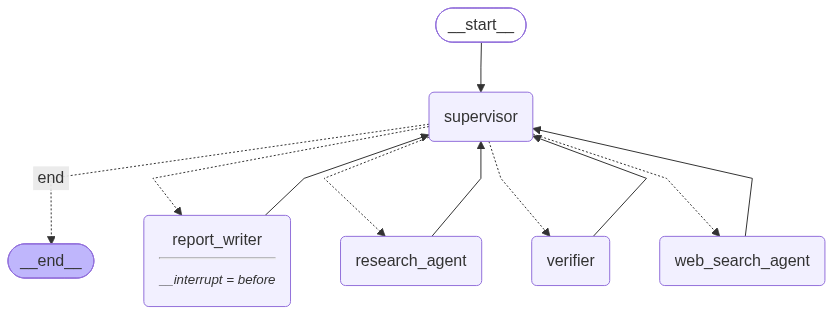

In [20]:
class ClaimCheck(BaseModel):
    index: int = Field(description='index of the key finding being checked (0-based)')
    supported: bool = Field(description='true if the sources support the claim')
    reason: str


class Verification(BaseModel):
    checks: list[ClaimCheck]


def verifier(state: ResearchState):
    # Task 14 guardrail: check every key finding against the sources; mark unsupported ones [UNVERIFIED]
    report = state['report'].model_copy(deep=True)
    if not report.citations and report.confidence_score < 0.3:        # fallback report: nothing to verify
        return {'verified': True, 'verification': [], 'report': report}
    sources = '\n\n'.join(state.get('retrieved_docs', [])) + '\n\n' + (state.get('web_findings') or '')
    claims = '\n'.join(f'{i}. {f}' for i, f in enumerate(report.key_findings))
    result = structured(Verification,
        f'Given these source documents:\n{sources[:7000]}\n\nverify each claim in this report:\n{claims}\n\n'
        'Flag any claims that cannot be supported by the sources (supported=false).',
        Verification(checks=[]))
    flagged = {c.index for c in result.checks if not c.supported and 0 <= c.index < len(report.key_findings)}
    report.key_findings = [('[UNVERIFIED] ' + f) if i in flagged else f for i, f in enumerate(report.key_findings)]
    if report.key_findings:
        report.confidence_score = round(report.confidence_score * (1 - 0.5 * len(flagged) / len(report.key_findings)), 2)
    return {'report': report, 'verified': True, 'verification': [c.model_dump() for c in result.checks],
            'messages': [AIMessage(content=f'[verifier] {len(flagged)} of {len(report.key_findings)} findings flagged',
                                   name='verifier')]}


def supervisor(state: ResearchState):
    if not state.get('research_done'):
        nxt = 'research_agent'
    elif state.get('needs_web_search') and not state.get('web_done'):
        nxt = 'web_search_agent'
    elif state.get('report') is None:
        nxt = 'report_writer'
    elif not state.get('verified'):
        nxt = 'verifier'
    else:
        nxt = 'end'
    return {'next': nxt}


builder = StateGraph(ResearchState)
for name, fn in [('supervisor', supervisor), ('research_agent', research_agent), ('web_search_agent', web_search_agent),
                 ('report_writer', report_writer), ('verifier', verifier)]:
    builder.add_node(name, fn)
builder.add_edge(START, 'supervisor')
builder.add_conditional_edges('supervisor', lambda s: s['next'],
                              {'research_agent': 'research_agent', 'web_search_agent': 'web_search_agent',
                               'report_writer': 'report_writer', 'verifier': 'verifier', 'end': END})
for name in ['research_agent', 'web_search_agent', 'report_writer', 'verifier']:
    builder.add_edge(name, 'supervisor')

# The checkpointer stores the Pydantic report, so those classes are allow-listed for (de)serialisation
checkpointer = MemorySaver(serde=JsonPlusSerializer(allowed_msgpack_modules=[('__main__', 'ResearchReport'),
                                                                              ('__main__', 'Citation')]))
research_graph = builder.compile(checkpointer=checkpointer, interrupt_before=['report_writer'])
mermaid = research_graph.get_graph().draw_mermaid()
print(mermaid)
try:
    from IPython.display import Image
    display(Image(research_graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print('(PNG rendering unavailable:', type(exc).__name__, ')')

---
# Milestone 2C: Human-in-the-loop and robustness
## Task 13: Human review gate
The graph pauses before `report_writer`. `review_and_run` shows the reviewer the findings and asks *"Approve and generate report? (yes / add more context / change query)"*:
- **yes**: sets `approved=True` and resumes into the report writer.
- **add more context**: stores the reviewer's text in `extra_context`, resets the research flags, and re-enters the graph **as the supervisor** (`update_state(..., as_node="supervisor")`), so the Research Agent runs again with the extra context.
- **change query**: restarts from the beginning on a new thread with the refined query.

For a reproducible notebook the reviewer's replies are scripted (`responses=[...]`) and printed as if typed. With `responses=None`, the function calls `input()` instead.

In [21]:
APPROVAL_PROMPT = 'Approve and generate report? (yes / add more context / change query)'


def show_findings(values):
    print(f"\n=== REVIEW GATE: findings for '{values['query']}' ===")
    print('Research analysis :', values.get('analysis', '')[:500])
    print('Passages retrieved:', ', '.join(f"{d['source']} p{d['page']} ({d['score']})" for d in values.get('doc_sources', [])))
    print('Web search used   :', values.get('needs_web_search'), '|', (values.get('web_findings') or '(none)')[:400])


def review_and_run(query, responses=None, thread_id=None, verbose=True):
    replies = iter(responses) if responses is not None else None
    thread_id = thread_id or f'thread-{time.time_ns()}'
    config = {'configurable': {'thread_id': thread_id}, 'recursion_limit': 30}
    research_graph.invoke({'query': query, 'messages': [HumanMessage(query)], 'approved': False}, config)
    while research_graph.get_state(config).next:
        values = research_graph.get_state(config).values
        if verbose:
            show_findings(values)
        reply = next(replies) if replies is not None else input(APPROVAL_PROMPT + ' ')
        if verbose:
            print(f'{APPROVAL_PROMPT}\nReviewer: {reply}')
        action, _, text = reply.partition(':')
        action = action.strip().lower()
        if action == 'yes':
            research_graph.update_state(config, {'approved': True})
            research_graph.invoke(None, config)
        elif action == 'add more context':
            extra = (values.get('extra_context', '') + ' ' + text.strip()).strip()
            research_graph.update_state(config, {'extra_context': extra, 'research_done': False, 'web_done': False,
                                                 'approved': False, 'next': 'research_agent'}, as_node='supervisor')
            research_graph.invoke(None, config)
        elif action == 'change query':
            remaining = list(replies) if replies is not None else None
            return review_and_run(text.strip(), remaining, verbose=verbose)
        else:
            print('Unrecognised reply; please answer yes / add more context / change query')
    return research_graph.get_state(config).values


def render_report(report: ResearchReport):
    lines = [f'### {report.title}', f'**Query:** {report.query}', f'**Confidence:** {report.confidence_score:.2f}',
             f'**Executive summary.** {report.executive_summary}', '**Key findings**']
    lines += [f'- {f}' for f in report.key_findings]
    lines += ['**Detailed analysis**', report.detailed_analysis]
    if report.data_points:
        lines += ['**Data points**'] + [f'- {k}: {v}' for k, v in report.data_points.items()]
    lines += ['**Citations**'] + [f'- {c.source}' + (f', p. {c.page}' if c.page else '') + f': "{c.quote}"'
                                  for c in report.citations]
    lines += ['**Knowledge gaps**'] + [f'- {g}' for g in report.knowledge_gaps]
    display(Markdown('\n\n'.join(lines)))

In [22]:
# Cycle 1: full approval
final_1 = review_and_run('How does Delta Lake provide ACID transactions on cloud object stores, and which problems '
                         'of the two-tier lake + warehouse architecture does that address?', responses=['yes'])
render_report(final_1['report'])


=== REVIEW GATE: findings for 'How does Delta Lake provide ACID transactions on cloud object stores, and which problems of the two-tier lake + warehouse architecture does that address?' ===
Research analysis : The provided passages discuss how Delta Lake provides ACID transactions on cloud object stores and address the limitations of the two-tier lake + warehouse architecture. The first passage explains that Delta Lake uses a log to store metadata and employs optimistic concurrency protocols to achieve transactions directly on the object store. This design allows for the implementation of features like time travel, which are not available in traditional cloud data lakes. The second passage further ela
Passages retrieved: delta_lake_vldb2020.pdf p2 (0.724), delta_lake_vldb2020.pdf p12 (0.72), delta_lake_vldb2020.pdf p12 (0.719), lakehouse_cidr2021.pdf p7 (0.709)
Web search used   : False | (none)
Approve and generate report? (yes / add more context / change query)
Reviewer: yes


### Delta Lake's ACID Transactions and Addressed Problems in Two-Tier Lake + Warehouse Architecture

**Query:** How does Delta Lake provide ACID transactions on cloud object stores, and which problems of the two-tier lake + warehouse architecture does that address?

**Confidence:** 0.79

**Executive summary.** Delta Lake provides ACID transactions on cloud object stores through its transactional design and optimistic concurrency protocols, addressing common pain points in the two-tier lake + warehouse architecture, such as the lack of ACID transactions and operational complexity.

**Key findings**

- Delta Lake uses optimistic concurrency protocols to achieve ACID transactions on cloud object stores.

- This design simplifies operations and ensures highly scalable reads and writes at the same cost as the underlying object store.

- [UNVERIFIED] Delta Lake addresses the lack of ACID transactions in the two-tier lake + warehouse architecture.

- It also simplifies operations and reduces the complexity of managing data across multiple systems.

**Detailed analysis**

Delta Lake, as described in [Source: delta_lake_vldb2020.pdf, Page: 2], provides ACID transactions on cloud object stores through its transactional design and optimistic concurrency protocols. Specifically, the log contains metadata such as min/max statistics for each data file, enabling faster metadata searches. Transactions are achieved using optimistic concurrency protocols against the object store, with some details varying by cloud provider. This design ensures that no servers need to be running to maintain state for a Delta table, and users only need to launch servers when running queries. The system is as highly available as the underlying cloud object store, making it operationally simple for users and ensuring scalable reads and writes at the same cost as the underlying object store. The design is feasible due to the nature of the workload, which is an OLAP workload with relatively few write transactions per second but large transaction sizes, which works well with the optimistic concurrency approach. This design addresses the lack of ACID transactions in the two-tier lake + warehouse architecture, as noted in [Source: lakehouse_cidr2021.pdf, Page: 7], where cloud-native data warehouses and data lake systems like Apache Hive cannot provide management features over data in data lakes, such as implementing ACID transactions.

**Data points**

- transactions: ACID transactions

- cloud_object_store: cloud object stores

- optimistic_concurrency: optimistic concurrency protocols

- metadata: min/max statistics for each data file

- operations: operationally simple for users

- scalability: highly scalable reads and writes at the same cost as the underlying object store

- availability: as highly available as the underlying cloud object store

**Citations**

- delta_lake_vldb2020.pdf, p. 2: "Crucially, we designed Delta Lake so that all the metadata is in the underlying object store, and transactions are achieved using optimistic concurrency protocols against the object store (with some details varying by cloud provider)."

- delta_lake_vldb2020.pdf, p. 12: "This design makes Delta Lake operationally simple for users and ensures highly scalable reads and writes at the same cost as the underlying object store. Moreover, the system is as highly available as the underlying cloud object store: no other components need to be hardened or restarted for disaster recovery."

- lakehouse_cidr2021.pdf, p. 7: "However, these systems cannot provide any management features over the data in data lakes (e.g., implement ACID transactions over it) the same way they do for their internal data, so using them with data lakes continues to be difficult and error-prone."

**Knowledge gaps**

- Specific details of the implementation of optimistic concurrency protocols for different cloud providers are not provided.

- The performance impact of the transactional design on write-heavy workloads is not discussed.

In [23]:
# Cycle 2: revision. The reviewer adds context, the Research Agent re-runs, then the reviewer approves.
final_2 = review_and_run('What are the main trade-offs of the lakehouse approach?',
                         responses=['add more context: Focus on query performance, and how a vectorized engine such '
                                    'as Photon helps a lakehouse match data warehouse speed.', 'yes'])
render_report(final_2['report'])


=== REVIEW GATE: findings for 'What are the main trade-offs of the lakehouse approach?' ===
Research analysis : The passages provided discuss several trade-offs associated with the lakehouse approach. Here are the main trade-offs highlighted in the documents:
Passages retrieved: lhbench_cidr2023.pdf p1 (0.56), lakehouse_cidr2021.pdf p6 (0.52), lakehouse_cidr2021.pdf p4 (0.504), lakehouse_cidr2021.pdf p7 (0.49)
Web search used   : False | (none)
Approve and generate report? (yes / add more context / change query)
Reviewer: add more context: Focus on query performance, and how a vectorized engine such as Photon helps a lakehouse match data warehouse speed.

=== REVIEW GATE: findings for 'What are the main trade-offs of the lakehouse approach?' ===
Research analysis : The provided passages discuss the lakehouse approach and its trade-offs, particularly focusing on query performance. They mention that lakehouse systems aim to provide an open interface for multiple engines to query the sam

### Trade-offs of the Lakehouse Approach

**Query:** What are the main trade-offs of the lakehouse approach?

**Confidence:** 0.90

**Executive summary.** The lakehouse approach combines the benefits of data lakes and data warehouses, but introduces trade-offs in terms of performance and management. Specifically, while lakehouse systems aim to provide an open interface for multiple engines, they may face challenges in achieving the same performance as traditional data warehouses. Vectorized engines like Photon can help mitigate some of these performance issues.

**Key findings**

- Lakehouse systems provide an open interface for multiple engines, including SQL workloads and other workloads such as machine learning and graph processing.

- Photon, a latency-optimized SQL engine, can help lakehouse systems match data warehouse speed.

- Lakehouse systems break down the traditional monolithic system design of data warehouses, providing a storage manager, table metadata, and transaction manager through client libraries.

- Achieving the primary goals of the lakehouse, such as building a massively parallel serving layer for a data warehouse, may be significantly more expensive and less performant than giving workloads direct access to the object store.

**Detailed analysis**

The lakehouse approach aims to combine the low-cost storage of data lakes with the powerful management and optimization features of data warehouses. However, this integration introduces trade-offs. According to [Source: lhbench_cidr2023.pdf, Page: 2], most of the CPU-hours on Databricks are used to process tables smaller than 1 TB, and query durations range from sub-second to hours. New latency-optimized SQL engines, such as Photon [24] and Presto [15], are expanding the range of data sizes and performance regimes that users can reach. This indicates that while Photon can help lakehouse systems match data warehouse speed, the performance trade-offs still exist. Additionally, [Source: lakehouse_cidr2021.pdf, Page: 6] suggests that building a massively parallel serving layer for a data warehouse may be significantly more expensive and less performant than giving workloads direct access to the object store. This highlights the cost and performance trade-offs inherent in the lakehouse approach. The open interface provided by lakehouse systems allows multiple engines to query the same data, but this may come at the cost of increased complexity and management overhead. Overall, the lakehouse approach offers a balanced solution, but it is not without its trade-offs.

**Data points**

- CPU-hours on Databricks: used to process tables smaller than 1 TB

- Query durations: range from sub-second to hours

- Photon: a latency-optimized SQL engine

- Cost and performance trade-offs: significantly more expensive and less performant

**Citations**

- lhbench_cidr2023.pdf, p. 2: "For example, most of the CPU-hours on Databricks are used to process tables smaller than 1 TB, and query durations across all tables range from sub-second to hours."

- lakehouse_cidr2021.pdf, p. 6: "However, we believe that such infrastructure will be significantly more expensive to run, harder to manage, and likely less performant than giving workloads direct access to the object store."

- lakehouse_cidr2021.pdf, p. 3: "Lakehouses thus combine the key benefits of data lakes and data warehouses: low-cost storage in an open format accessible by a variety of systems from the former, and powerful management and optimization features from the latter."

**Knowledge gaps**

- Specific cost comparisons between direct access to object store and serving layer infrastructure

- Detailed performance benchmarks between Photon and traditional data warehouse engines

In [24]:
# Cycle 3: the reviewer changes a vague query into a precise one; the run restarts from the beginning
final_3 = review_and_run('Tell me about streaming.',
                         responses=['change query: How does Structured Streaming provide end-to-end exactly-once '
                                    'guarantees?', 'yes'])
render_report(final_3['report'])


=== REVIEW GATE: findings for 'Tell me about streaming.' ===
Research analysis : The provided passages discuss challenges and aspects of streaming systems, particularly focusing on the difficulties users face when developing and operating these systems. They mention that streaming systems often require users to think about complex execution concepts and that many systems focus only on streaming computation, which can be insufficient for end-to-end business applications. The passages also highlight that Structured Streaming, a system developed to address these challenges, out
Passages retrieved: structured_streaming_sigmod2018.pdf p2 (0.615), structured_streaming_sigmod2018.pdf p2 (0.593), structured_streaming_sigmod2018.pdf p2 (0.575), structured_streaming_sigmod2018.pdf p1 (0.567)
Web search used   : False | (none)
Approve and generate report? (yes / add more context / change query)
Reviewer: change query: How does Structured Streaming provide end-to-end exactly-once guarantees?

===

### How Does Structured Streaming Provide End-to-End Exactly-Once Guarantees?

**Query:** How does Structured Streaming provide end-to-end exactly-once guarantees?

**Confidence:** 0.90

**Executive summary.** Structured Streaming achieves end-to-end exactly-once guarantees through fault tolerance mechanisms and strong consistency semantics. It ensures that input records are processed in the correct order and that results reflect all input records. The system uses a write-ahead log and a state store for fault tolerance, allowing recovery on failure. Watermarks are used to manage state for old windows.

**Key findings**

- Structured Streaming uses replayable input sources and a write-ahead log to ensure fault tolerance and exactly-once processing.

- The system guarantees that input records are processed in the correct order and that results reflect all input records.

- Watermarks are used to manage state for old windows, allowing the system to forget state for records that are considered outdated.

- A state store is used to hold snapshots of operator states for long-running aggregation operators, ensuring consistent recovery.

**Detailed analysis**

Structured Streaming provides end-to-end exactly-once guarantees through a combination of fault tolerance mechanisms and strong consistency semantics. According to the paper [Source: structured_streaming_sigmod2018.pdf, Page: 5], Structured Streaming ensures that input records are processed in the correct order and that results reflect all input records. Specifically, the system guarantees that when input records are relatively ordered within a source, the system will only produce results that incorporate them in the same order (e.g., never skipping a record). Additionally, the system uses a write-ahead log to keep track of processed data and a state store to hold snapshots of operator states, ensuring consistent recovery on failure [Source: structured_streaming_sigmod2018.pdf, Page: 4]. Watermarks are used to manage state for old windows, allowing the system to forget state for records that are considered outdated [Source: structured_streaming_sigmod2018.pdf, Page: 5].

**Data points**

- replayable input sources: Yes

- write-ahead log: Yes

- state store: Yes

- watermarks: Yes

**Citations**

- structured_streaming_sigmod2018.pdf, p. 5: "First, it guarantees that when input records are relatively ordered within a source (e.g., log records from the same device), the system will only produce results that incorporate them in the same records (e.g., never skipping a record)."

- structured_streaming_sigmod2018.pdf, p. 4: "The system uses a write-ahead log to keep track of which data has been processed and reliably written to the output sink from each input source. For some output sinks, this log can be integrated with the sink to make updates to the sink atomic."

- structured_streaming_sigmod2018.pdf, p. 5: "Watermarks are used to manage state for old windows, allowing the system to forget state for records that are considered outdated."

**Knowledge gaps**

- The exact mechanism of how the write-ahead log and state store are integrated for atomic updates is not detailed in the provided evidence.

**What the three review cycles show**
- **Cycle 1 (approve):** the research agent found four on-topic passages (Delta Lake pp. 2 and 12, Lakehouse p. 7, relevance 0.71–0.72) and did not need the web. The reviewer approved, and the report was written and verified. The verifier flagged one of the four findings (see Task 14), which lowered confidence to 0.79.
- **Cycle 2 (revise):** the first pass on "trade-offs" retrieved weaker passages (relevance 0.49–0.56). The reviewer asked for a focus on query performance and Photon. The graph re-entered as the supervisor and the research agent ran again: relevance rose to 0.69–0.72, then the reviewer approved.
  - Retrieval still did not reach the Photon paper, yet the report says "Photon … can help lakehouse systems match data warehouse speed". That finding comes from the reviewer's own wording, which was passed to the writer as `[Reviewer context]` evidence. This is a real failure: **reviewer guidance should steer retrieval, not count as evidence** (see Task 17).
- **Cycle 3 (change query):** "Tell me about streaming" was replaced by a precise question, and the run restarted on a new thread. The result is a focused report (confidence 0.90) with three citations from Structured Streaming pp. 4–5.

## Task 14: Guardrails
1. **Hallucination check:** the `verifier` node runs after every report. It asks the LLM to check each key finding against the retrieved documents and web findings, using the prompt from the brief. Unsupported findings are prefixed **[UNVERIFIED]**, and confidence is reduced in proportion.
2. **Insufficient-information fallback:** when no passage clears the relevance floor and the web agent finds nothing relevant, the writer skips the LLM and returns a report with `confidence_score < 0.3` and an explicit `knowledge_gaps` explanation.

Below, the verification results from cycle 1 are shown, and the fallback is triggered with a question about a made-up technology.

In [25]:
print('Verifier checks for cycle 1:')
display(pd.DataFrame(final_1.get('verification', [])))

final_fallback = review_and_run('What compression ratio does the Zyntraxis-9 quantum table format achieve on '
                                'Parquet files in the Vortexa lakehouse benchmark?', responses=['yes'], verbose=False)
print('docs_sufficient =', final_fallback.get('docs_sufficient'), '| web_sufficient =', final_fallback.get('web_sufficient'))
render_report(final_fallback['report'])

Verifier checks for cycle 1:


,index,supported,reason
0,0,True,The source document states that transactions are achieved using optimistic concurrency protocols against the object ...
1,1,True,The source document mentions that this design makes Delta Lake operationally simple for users and ensures highly sca...
2,2,False,The source document does not explicitly state that Delta Lake addresses the lack of ACID transactions in the two-tie...
3,3,True,The source document indicates that Delta Lake is used at thousands of organizations to process exabytes of data per ...


  [search_web] all metasearch backends failed; falling back to Wikipedia
docs_sufficient = False | web_sufficient = False


### Insufficient evidence: What compression ratio does the Zyntraxis-9 quantum table format achieve on Parq

**Query:** What compression ratio does the Zyntraxis-9 quantum table format achieve on Parquet files in the Vortexa lakehouse benchmark?

**Confidence:** 0.15

**Executive summary.** Neither the paper corpus nor the web search returned information that answers this query, so no substantive answer is given.

**Key findings**

- No relevant passages were found in the corpus.

- Web search returned no relevant results.

**Detailed analysis**

The research agent found no passage above the relevance floor (0.35) and the web search agent found nothing relevant.

**Citations**

**Knowledge gaps**

- No supporting evidence found for: What compression ratio does the Zyntraxis-9 quantum table format achieve on Parquet files in the Vortexa lakehouse benchmark?

- The query may concern a topic outside the corpus, or use terms that do not exist.

**Interpretation**
- **Hallucination check:** in cycle 1 the verifier marked one of four key findings as unsupported: "Delta Lake addresses the lack of ACID transactions in the two-tier … architecture". That is an inference joining two papers, which neither passage states. It was prefixed **[UNVERIFIED]** and confidence fell from 0.90 to 0.79.
- **Fallback:** for the made-up "Zyntraxis-9" format, the research agent judged that none of the retrieved passages were about the asked-for system. The web search found nothing relevant (the metasearch engines failed from Colab, and the Wikipedia fallback had no match). The writer therefore skipped the LLM and returned the fallback report: **confidence 0.15**, no citations, and explicit knowledge gaps.
- In the first development run, before the topic check existed, the same question produced a confident report that attributed Photon and Delta Lake numbers to the non-existent format. The topic check is what fixed it.

---
# Milestone 2D: Evaluation and analysis
## Task 15: End-to-end evaluation on the 10 evaluation questions
Each query goes through the full system, with the review gate auto-approved so that latency is not distorted by human wait time.

| Metric | How it is measured here |
|---|---|
| Retrieval hit | Is the question's source paper among the Research Agent's top-4 passages? |
| Faithfulness (1–5) | Claim-level LLM judge (Llama 3.1 8B): the answer is split into atomic claims, each is marked supported or not by the context, and the score is 1 + 4 × (share supported) |
| Relevance (1–5) | Same judge, anchored rubric: does the report answer every part of the question? |
| Citation accuracy | Automated version of the manual check: share of citations whose file exists, whose page is in range, and whose quote appears on that page (fuzzy, ≥ 60% of the words) |
| Latency | Wall-clock seconds from query to final verified report |
| Tokens / cost | Input + output tokens from LangChain's usage callback. Actual cost is \$0 (local model); the gpt-4o-mini equivalent is shown for reference |

In [26]:
class ClaimVerdict(BaseModel):
    claim: str
    supported: bool = Field(description='true only if the context states this claim')


class ClaimJudgement(BaseModel):
    claims: list[ClaimVerdict] = Field(description='every factual claim made in the ANSWER (not in the context)')
    relevance: int = Field(description='1-5: 5 = answers every part of the question with specifics, 4 = answers the '
                                       'main point but misses a detail, 3 = partial, 2 = mostly off-target, '
                                       '1 = does not answer the question')


CLAIM_TEMPLATE = ChatPromptTemplate.from_messages([
    ('system', 'You are a strict evaluator of a research assistant. Return JSON only.'),
    ('human', 'Question: {question}\n\nContext available to the system:\n{context}\n\nAnswer:\n{answer}\n\n'
              'List the individual factual claims made in the ANSWER. For each, set supported=true only if the '
              'context states it. Then rate how well the answer addresses the question (relevance 1-5).')])


def judge_report(question, context, answer):
    # Returns (faithfulness 1-5 from the share of supported claims, relevance 1-5, claim verdicts)
    judgement = structured(ClaimJudgement, CLAIM_TEMPLATE.format(question=question, context=context[:7000],
                                                                 answer=answer[:4000]),
                           None, model=judge_llm)
    if judgement is None or not judgement.claims:
        return None, None, []
    share = sum(c.supported for c in judgement.claims) / len(judgement.claims)
    return round(1 + 4 * share, 2), clamp_score(judgement.relevance), judgement.claims


PAGE_TEXT = {(p.metadata['source'], p.metadata['page']): p.page_content.lower() for p in pages}


def citation_accuracy(report, web_text=''):
    if not report.citations:
        return np.nan
    ok = 0
    for c in report.citations:
        words = re.findall(r'[a-z0-9]+', c.quote.lower())
        if c.source in TITLES:
            text = PAGE_TEXT.get((c.source, c.page or -1), '')
        else:
            text = web_text.lower() if c.source.startswith('http') and c.source in web_text else ''
        if text and words:
            ok += sum(w in text for w in words) / len(words) >= 0.6
    return ok / len(report.citations)


def report_text(report):
    return '\n'.join([report.executive_summary, *report.key_findings, report.detailed_analysis])


# Judge sanity check: a real report, the same report with one injected false claim, and an off-topic answer
calib_context = '\n\n'.join(final_1.get('retrieved_docs', []))
calib_answer = report_text(final_1['report'])
calibration = []
for label, answer in [('original report', calib_answer),
                      ('+ injected false claim', calib_answer + '\nDelta Lake stores its transaction log in a MySQL '
                                                 'database managed by the Hive metastore.'),
                      ('off-topic answer', 'Apache Kafka is a distributed event streaming platform originally '
                                           'developed at LinkedIn.')]:
    faith, rel, claims = judge_report(final_1['query'], calib_context, answer)
    calibration.append({'answer': label, 'faithfulness': faith, 'relevance': rel, 'claims': len(claims),
                        'flagged as unsupported': [c.claim[:90] for c in claims if not c.supported]})
pd.DataFrame(calibration)

,answer,faithfulness,relevance,claims,flagged as unsupported
0,original report,3.40,5,5,"[Delta Lake addresses the lack of ACID transactions in the two-tier lake + warehouse archit, It also simplifies oper..."
1,+ injected false claim,4.38,5,13,"[It also simplifies operations and reduces the complexity of managing data across multiple , Delta Lake stores its t..."
2,off-topic answer,3.00,1,2,[Apache Kafka is a distributed event streaming platform]


The judge passes the sanity check if it flags the injected MySQL claim and gives the off-topic answer low relevance. Its scores below should be read with that calibration in mind. It is a small local model, and an 8B judge is more lenient than a human reviewer.

In [27]:
eval_rows, eval_reports = [], {}
for q in EVAL_SET:
    final, seconds, tin, tout = tracked(review_and_run, q['question'], ['yes'], None, False)
    report = final['report']
    context = '\n\n'.join(final.get('retrieved_docs', [])) + '\n\n' + (final.get('web_findings') or '')
    faith, rel, _ = judge_report(q['question'], context, report_text(report))
    eval_reports[q['id']] = final
    eval_rows.append({'id': q['id'], 'question': q['question'][:60] + '...',
                      'hit': q['source'] in [d['source'] for d in final.get('doc_sources', [])],
                      'web_used': final.get('needs_web_search'), 'faithfulness': faith, 'relevance': rel,
                      'citation_acc': citation_accuracy(report, final.get('web_findings') or ''),
                      'n_citations': len(report.citations), 'confidence': report.confidence_score,
                      'unverified': sum(f.startswith('[UNVERIFIED]') for f in report.key_findings),
                      'latency_s': round(seconds, 1), 'tokens_in': tin, 'tokens_out': tout,
                      'gpt4o_mini_equiv_$': (tin * PRICE_IN + tout * PRICE_OUT) / 1e6})

e2e = pd.DataFrame(eval_rows).set_index('id')
e2e['score'] = (e2e['hit'].astype(float) + e2e['faithfulness'].fillna(0) / 5 + e2e['relevance'].fillna(0) / 5
                + e2e['citation_acc'].fillna(0))
e2e.round(3)

  [structured output for ResearchReport repaired from raw JSON]


,question,hit,web_used,faithfulness,relevance,citation_acc,n_citations,confidence,unverified,latency_s,tokens_in,tokens_out,gpt4o_mini_equiv_$,score
id,,,,,,,,,,,,,,
Q1,How does MapReduce handle the failure of a worker machine?...,True,False,4.2,5,1.0,3,0.79,1,48.9,2910,1178,0.001,3.84
Q2,Why does the Google File System use a large 64 MB chunk size...,True,False,5.0,5,1.0,2,0.90,0,43.9,3210,1016,0.001,4.00
Q3,How do Resilient Distributed Datasets recover lost data with...,True,False,5.0,5,1.0,2,0.90,0,35.1,2875,809,0.001,4.00
Q4,What is the Catalyst optimizer in Spark SQL and what phases ...,True,False,5.0,5,NaN,0,0.50,0,100.0,2530,2411,0.002,3.00
Q5,How does Dremel store nested records in a columnar format?...,True,False,5.0,5,1.0,1,0.90,0,45.9,2767,1078,0.001,4.00
Q6,What is the main idea behind the Structured Streaming progra...,True,False,5.0,5,1.0,3,0.90,0,53.9,2564,1276,0.001,4.00
Q7,How does Delta Lake implement ACID transactions on cloud obj...,True,False,5.0,5,1.0,2,0.90,0,43.6,2627,966,0.001,4.00
Q8,What problems with the two-tier data lake plus data warehous...,True,False,5.0,5,1.0,3,0.90,0,86.3,2986,1345,0.001,4.00
Q9,How does Deequ let users define and verify data quality chec...,True,False,5.0,5,1.0,2,0.90,0,42.6,2097,1018,0.001,4.00


In [28]:
averages = e2e[['hit', 'web_used', 'faithfulness', 'relevance', 'citation_acc', 'confidence', 'latency_s',
                'tokens_in', 'tokens_out', 'gpt4o_mini_equiv_$']].astype(float).mean()
print('Averages over', len(e2e), 'queries')
display(averages.round(3).to_frame('mean').T)
print(f"Total tokens: {int(e2e['tokens_in'].sum()):,} in / {int(e2e['tokens_out'].sum()):,} out | "
      f"actual cost $0.00 (local) | gpt-4o-mini equivalent ${e2e['gpt4o_mini_equiv_$'].sum():.4f}")

ranked = e2e.sort_values('score', ascending=False)
best_ids, worst_ids = list(ranked.index[:2]), list(ranked.index[-2:])
print('Best 2 :', best_ids, '| Worst 2:', worst_ids)
for qid in best_ids + worst_ids:
    final = eval_reports[qid]
    print(f"\n----- {qid} ({'best' if qid in best_ids else 'worst'}) : {final['query']}")
    print('Top passages:', [(d['source'], d['page'], d['score']) for d in final['doc_sources']])
    print('Executive summary:', final['report'].executive_summary)
    print('Findings:', *final['report'].key_findings, sep='\n  - ')

Averages over 10 queries


,hit,web_used,faithfulness,relevance,citation_acc,confidence,latency_s,tokens_in,tokens_out,gpt4o_mini_equiv_$
mean,1.0,0.0,4.82,5.0,1.0,0.834,57.81,2737.6,1296.9,0.001


Total tokens: 27,376 in / 12,969 out | actual cost $0.00 (local) | gpt-4o-mini equivalent $0.0119
Best 2 : ['Q2', 'Q3'] | Worst 2: ['Q10', 'Q4']

----- Q2 (best) : Why does the Google File System use a large 64 MB chunk size?
Top passages: [('gfs_sosp2003.pdf', 3, 0.657), ('gfs_sosp2003.pdf', 11, 0.652), ('gfs_sosp2003.pdf', 4, 0.612), ('gfs_sosp2003.pdf', 1, 0.593)]
Executive summary: The Google File System (GFS) uses a large 64 MB chunk size to reduce client-master interactions, especially for sequential reads and writes, and to avoid internal fragmentation. This design choice simplifies the system, enhances reliability, and improves performance.
Findings:
  - Reduces client-master interactions for sequential reads and writes.
  - Avoids internal fragmentation, which is a significant advantage of large chunk sizes.
  - Simplifies the system and enhances reliability.
  - Improves performance by minimizing the number of interactions required for file operations.

----- Q3 (best) : How 

**Interpretation**
- **Retrieval hit rate 10/10.** The source paper was always in the research agent's top 4. **Web search was used 0/10 times**, which is correct, since every question is answerable from the corpus.
- **Faithfulness 4.82 / 5 on average.** Eight reports had every claim supported. Q1 (4.2) and Q10 (4.0) each contain a claim the judge could not match to the retrieved text, and the verifier had already marked those findings [UNVERIFIED]. **Relevance is 5/5 everywhere**, a ceiling effect of the 8B judge.
- **Citation accuracy: 100% for the 9 reports that have citations.** Every citation names a real file and an in-range page, with a quote that appears on that page. In the previous run this metric was 11%: Qwen wrote the whole tag `[Source: x.pdf, Page: 4]` into the `source` field. `normalize_citation()` now repairs that (Task 17).
- **Latency: 58 s on average** (35–100 s on a T4). **Tokens: about 2.7k in and 1.3k out per query.** The actual cost is **$0** on the local GPU. The same tokens would cost about **$0.0012 per query** at gpt-4o-mini list prices.
- **Best (Q2, Q3):** all four passages came from one paper, the answer is short and factual, and every claim and citation checks out.
- **Worst:**
  - **Q10:** the verifier and the judge both flagged "selectively compacts sparse batches". It is in the Photon paper, but not in the four retrieved chunks, so it is ungrounded *for this context*.
  - **Q4:** the longest output (2,411 tokens) hit the writer's 2,048-token cap. `json_repair` saved the report but lost the citation list (0 citations, confidence 0.50). The report also mixed in Structured Streaming's planning stages from a neighbouring chunk.
- **Judge reliability:** the calibration cell shows the judge catches an injected false claim and scores an off-topic answer 1 for relevance. Its claim splitting is unstable, though (5 vs 13 claims for nearly the same text), so faithfulness scores are good for spotting fabrications but too coarse to rank close systems.

## Task 16: Ablation study
The same five representative queries are run through four configurations. Four come from the evaluation set and one needs current information (Type B), so the configurations that can reach the web have something to show. The same judge scores faithfulness against whatever context each configuration actually saw.

In [29]:
ABLATION_QUERIES = [EVAL_SET[i]['question'] for i in (1, 4, 6, 7)] + [REACT_QUERIES['Type B (documents + web)']]
mmr_chain = make_rag_chain(retrievers['B: MMR, k=4, fetch_k=15'])


def run_config(config, query):
    if config in ('Baseline RAG', 'RAG + MMR'):
        out = (rag_chain if config == 'Baseline RAG' else mmr_chain).invoke(query)
        return out['answer'], format_docs(out['docs'])
    if config == 'ReAct Agent':
        out = run_react(query)
        return out['answer'], out['context']
    final = review_and_run(query, ['yes'], verbose=False)
    context = '\n\n'.join(final.get('retrieved_docs', [])) + '\n\n' + (final.get('web_findings') or '')
    return report_text(final['report']), context


ablation_rows = []
for config in ['Baseline RAG', 'RAG + MMR', 'ReAct Agent', 'Full System']:
    for i, query in enumerate(ABLATION_QUERIES):
        (answer, context), seconds, tin, tout = tracked(run_config, config, query)
        faith, rel, _ = judge_report(query, context, answer)
        ablation_rows.append({'config': config, 'query': i + 1, 'faithfulness': faith, 'relevance': rel,
                              'latency_s': seconds, 'tokens': tin + tout})

ablation = pd.DataFrame(ablation_rows)
ablation_summary = (ablation.groupby('config', sort=False)[['faithfulness', 'relevance', 'latency_s', 'tokens']]
                    .mean().round(2))
display(ablation_summary)
ablation.pivot(index='query', columns='config', values=['faithfulness', 'relevance'])

,faithfulness,relevance,latency_s,tokens
config,,,,
Baseline RAG,4.68,4.4,6.35,1054.2
RAG + MMR,4.68,4.4,6.01,1111.0
ReAct Agent,4.84,5.0,11.46,3084.6
Full System,4.73,5.0,42.59,3678.0


faithfulness                                      relevance                                  
config Baseline RAG Full System RAG + MMR ReAct Agent Baseline RAG Full System RAG + MMR ReAct Agent
query                                                                                               
1               5.0        5.00      5.00         4.6          5.0         5.0       5.0         5.0
2               5.0        5.00      4.56         5.0          5.0         5.0       5.0         5.0
3               5.0        5.00      5.00         5.0          5.0         5.0       5.0         5.0
4               5.0        4.33      5.00         4.6          5.0         5.0       5.0         5.0
5               3.4        4.33      3.86         5.0          2.0         5.0       2.0         5.0

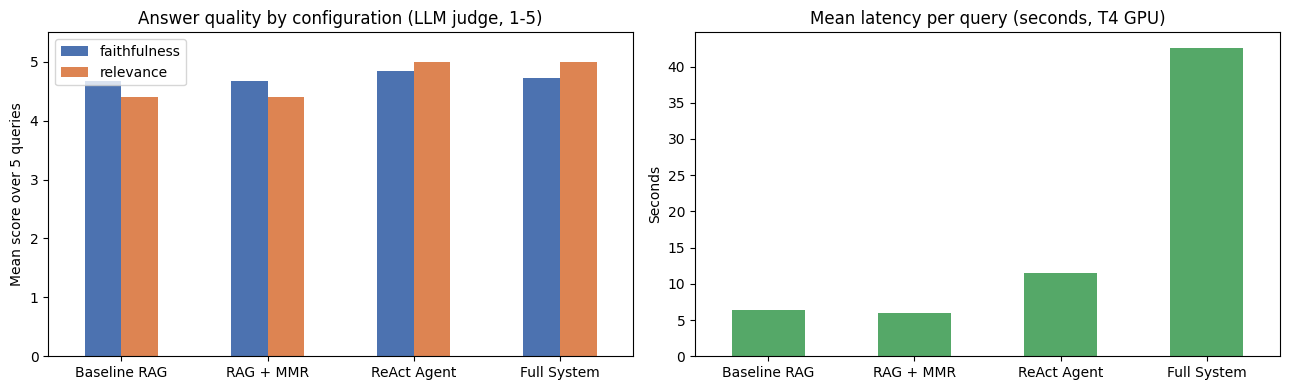

In [30]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ablation_summary[['faithfulness', 'relevance']].plot.bar(ax=axes[0], color=['#4C72B0', '#DD8452'], rot=0)
axes[0].set_title('Answer quality by configuration (LLM judge, 1-5)')
axes[0].set_ylim(0, 5.5)
axes[0].set_ylabel('Mean score over 5 queries')
axes[0].set_xlabel('')
ablation_summary['latency_s'].plot.bar(ax=axes[1], color='#55A868', rot=0)
axes[1].set_title('Mean latency per query (seconds, T4 GPU)')
axes[1].set_ylabel('Seconds')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

**Interpretation**

| Configuration | Faithfulness | Relevance | Latency | Tokens |
|---|---|---|---|---|
| Baseline RAG | 4.68 | 4.4 | 6.4 s | 1.1k |
| RAG + MMR | 4.68 | 4.4 | 6.0 s | 1.1k |
| ReAct Agent | 4.84 | 5.0 | 11.5 s | 3.1k |
| Full System | 4.73 | 5.0 | 42.6 s | 3.7k |

- On the four corpus questions, all configurations score at or near 5. **Query 5 (the Delta Lake "newer features" question) separates them.** Both plain RAG chains can only say what the 2020 paper says (relevance 2). The ReAct agent and the full system reach the web and answer it (relevance 5).
- **MMR made no measurable difference** here, consistent with Task 5. The corpus is too small for diversity to matter.
- **The ReAct agent gives the best quality per second** for interactive Q&A: about 2× the latency of plain RAG.
- **The full system is about 7× slower than RAG and 4× slower than ReAct.** It makes four to six LLM calls: the sufficiency decision, the web query and summary, a long structured report, and verification. It does not score higher on the judge. What it buys is a **structured, cited, verified report with a human approval step and an explicit low-confidence fallback**: auditability rather than raw answer quality.
- **Trade-off:** use plain RAG for fast lookups over the corpus, ReAct for questions that may need fresh information, and the full pipeline when the output is a report someone will rely on.

## Task 17: Failure analysis
Three probe queries, chosen from the failure patterns seen above, are run through the system so that each failure can be reproduced.

In [31]:
PROBES = {
    'F1 ambiguous entity -> retrieval confusion': 'How does the system from Google handle slow machines (stragglers)?',
    'F2 numeric detail -> unsupported numbers': 'Exactly how much faster than Databricks Runtime was Photon on TPC-DS, and on how many nodes?',
    'F3 agent tool choice': 'How does Spark SQL\'s Catalyst optimizer work?',
}
probe_results = {}
for label, query in PROBES.items():
    print(f'##### {label}\nQuery: {query}')
    if label.startswith('F3'):
        probe_results[label] = run_react(query)
        print_trace(probe_results[label])
    else:
        final = review_and_run(query, ['yes'], verbose=False)
        probe_results[label] = final
        print('Top passages:', [(d['source'], d['page'], d['score']) for d in final['doc_sources']])
        print('Web used:', final.get('needs_web_search'), '| confidence:', final['report'].confidence_score)
        print('Findings:', *final['report'].key_findings, sep='\n  - ')
        print('Data points:', final['report'].data_points)
        print('Verifier:', final.get('verification'))
        print()

##### F1 ambiguous entity -> retrieval confusion
Query: How does the system from Google handle slow machines (stragglers)?
Top passages: [('dremel_vldb2010.pdf', 1, 0.679), ('dremel_vldb2010.pdf', 7, 0.651), ('gfs_sosp2003.pdf', 11, 0.617), ('mapreduce_osdi2004.pdf', 6, 0.604)]
Web used: False | confidence: 0.9
Findings:
  - Google uses shared clusters of commodity machines for massively parallel computing, which inherently includes handling stragglers.
  - The Dremel system employs a mechanism to deal with stragglers by scheduling backup executions of tasks when the primary execution is slow or fails.
  - The MapReduce system also handles stragglers by scheduling backup tasks when a machine is slow or fails, ensuring faster overall execution.
Data points: {'stragglers': 'stragglers are machines that take much longer to execute a given task than others or may never complete due to failures or preemption by the cluster management system', 'backup_executions': 'backup executions of tasks

  [search_web] all metasearch backends failed; falling back to Wikipedia
Top passages: [('photon_sigmod2022.pdf', 11, 0.705), ('photon_sigmod2022.pdf', 11, 0.7), ('photon_sigmod2022.pdf', 11, 0.695), ('photon_sigmod2022.pdf', 1, 0.694)]
Web used: True | confidence: 0.5
Findings:
  - Photon achieved a maximum speedup of 23× and an average speedup of 4× on the TPC-H benchmark across 8 nodes.
  - Photon was used to set a new audited performance record for the official 100TB TPC-DS benchmark.
  - [UNVERIFIED] The exact speedup on the 100TB scale factor with 256 nodes is not specified in the provided evidence.
Data points: {'maximum_speedup': '23×', 'average_speedup': '4×', 'nodes_used_for_speedup': '8'}
Verifier: [{'index': 0, 'supported': True, 'reason': 'The document states that Photon achieves a maximum speedup of 23× and an average speedup of 4× across all queries on the TPC-H benchmark.'}, {'index': 1, 'supported': True, 'reason': 'The document mentions that Photon has recently allowe

**Three failure modes observed, with a reproducer and a mitigation for each**

| # | Failure | Example that triggers it | What went wrong | Mitigation |
|---|---|---|---|---|
| **F1** | **Ambiguous entity, silently merged** | "How does the system from Google handle slow machines (stragglers)?" | Four papers describe Google systems. Retrieval returned Dremel, GFS and MapReduce chunks, and the report merged their straggler handling into one answer (confidence 0.90). The pipeline never asked *which* system. The verifier also returned no checks at all, and an empty result was treated as "nothing to flag". | Add an ambiguity check before research (the ReAct v1 agent already asks for clarification). Treat an empty or failed verifier result as *unverified* and lower confidence, rather than passing it. |
| **F2** | **Right numbers, wrong benchmark** | "Exactly how much faster than Databricks Runtime was Photon on TPC-DS, and on how many nodes?" | The paper reports 23× max / 4× average speedup **on TPC-H** with 8 nodes. The report put those numbers in `data_points` as the answer to a TPC-DS question. The verifier marked the claims *supported*, because the numbers are in the source: it checks support, not whether a claim answers the question. Only the 256-node TPC-DS gap was flagged. | Make the writer attach the benchmark or entity to every data point, and add a verifier check that each data point refers to the entity asked about. Report "not found for TPC-DS" as a knowledge gap. |
| **F3** | **Tool-choice errors in the free-form agent** | Task 10: "What is the latest stable release of Apache Iceberg…?" and the Delta Lake "newer features" question | Llama 3.1 8B (prompt v1) answered the Iceberg question **from memory with a wrong version**, and never used the web. Qwen with prompt v2 skipped the web on the Type B question. The F3 probe above (Catalyst) shows the final agent behaving correctly on a documents-only question, so the failure is specific to *when to escalate*. | Use the stronger tool-calling model, and keep the escalation decision outside free-form ReAct. The multi-agent graph does this with a structured `needs_web_search` decision. Add a post-check: if the answer contains a version or date and no `[Web: …]` citation, force a web search. |

**Other failures found and fixed during development:**
- **Citation format drift:** Qwen wrote the whole tag into `Citation.source`, and citation accuracy was 11% in run 2. `normalize_citation()` fixed it.
- **Truncated report JSON:** fixed with a 2,048-token budget, `include_raw` and `json_repair`. Q4 shows the remaining risk, a lost citation list.
- **Reviewer-context laundering:** in HITL cycle 2 the reviewer's guidance surfaced as a finding. The mitigation is to pass reviewer text only to the retriever and the sufficiency check, not to the writer's evidence or the verifier's sources.

---
## Summary
- **RAG foundation:** 13 papers (167 pages) → 1,266 chunks of about 1,000 characters → MiniLM embeddings in a persisted Chroma store. Similarity retrieval found the right paper first for 20 of 20 questions, including paraphrases that do not name the system.
- **Prompting:** a role-based expert prompt with two worked examples gave the most accurate and most consistently formatted answers (bullets 0% → 90%, citations 100%).
- **Agents:** model choice mattered more than prompt wording. Qwen 2.5 7B handled all four query types; Llama 3.1 8B did not escalate to the web and once invented a version number.
- **Multi-agent system:** a supervisor-routed LangGraph with a human review gate (approve, revise, change query), a claim verifier and an explicit low-confidence fallback. Across 10 questions: 100% retrieval hits, faithfulness 4.8/5, 100% valid citations where present, about 58 s per report, $0 cost on a free T4.
- **Main weaknesses:** silent merging of ambiguous entities, numbers attached to the wrong benchmark, and an 8B judge that is too lenient to rank close systems. The report (`MiniProject_report.md`) discusses mitigations and what production would need.